# Proyecto final · Econometría Financiera
**Modelos econométricos del portafolio en HowTheMarketWorks**

Carlos Salvide · A01452194 · Prof. Raymundo Diaz · EGADE Business School

Contenido:
1. Datos diarios, por hora (60 min) y por minuto (5 y 1 min)
2. Portafolio: número de acciones, valor y pesos
3. Regresión lineal simple (CAPM) por frecuencia
4. Regresión lineal múltiple y horas seleccionadas
5. Datos panel con reportes trimestrales
6. Series de tiempo: metodología Box-Jenkins (AR, MA, ARMA, ARIMA) y forecast
7. GARCH
8. Estrategias del portafolio
9. Conclusiones y reporte HTML / Word

## 0. Parámetros

In [1]:
ALUMNO      <- "Carlos Salvide"
MATRICULA   <- "A01452194"
PROFESOR    <- "Raymundo Diaz"
MATERIA     <- "Econometría Financiera"
INSTITUCION <- "EGADE Business School · Tecnológico de Monterrey"

PORTAFOLIO <- data.frame(
  ticker        = c("COST", "KOF", "GOOG", "NVDA", "TGT", "BAC", "MSFT", "AMZN", "AAPL"),
  empresa       = c("Costco", "Coca-Cola FEMSA", "Alphabet", "NVIDIA", "Target",
                    "Bank of America", "Microsoft", "Amazon", "Apple"),
  acciones      = c(300, 1000, 100, 100, 50, 150, 10, 10, 1),
  precio_pagado = c(988.12, 108.15, 340.32, 241.74, 153.59, 54.64, 531.86, 251.55, 333.39),
  stringsAsFactors = FALSE)
TICKERS  <- PORTAFOLIO$ticker
CUENTA_HTMW <- c(`Efectivo inicial` = 1000000, `Efectivo disponible` = 514127.84, `Valor de las posiciones` = 519601.22,
                 `Valor total de la cuenta` = 1015257.81, `Rendimiento de la cuenta %` = 1.53,
                 `Rendimiento del SPY en el mismo periodo %` = -4.90, Comisiones = 120, `Dividendos cobrados` = 1083.83,
                 `Operaciones realizadas` = 12)
BENCH    <- "^GSPC"
BENCH_ID <- "SPY"
FACTORES <- c(Mercado = "^GSPC", VIX = "^VIX", Tasa10Y = "^TNX", USDMXN = "MXN=X", Petroleo = "CL=F")
RF <- 0.04
H_DIAS <- 10; H_HORAS <- 7; H_5M <- 12; H_1M <- 30

LINK_COLAB   <- "https://colab.research.google.com/drive/1ErHpG2S5Sf7DTRsmbjekwdNcrcA0cfZP?usp=sharing"
LINK_GITHUB  <- "https://github.com/CSalvide/econometria-financiera-portafolio"
LINK_COPILOT <- "https://github.com/CSalvide/econometria-financiera-portafolio/blob/main/PROMPT_COPILOT.md"

SALIDA <- "salidas"; CAPTURAS <- "capturas"
dir.create(SALIDA, showWarnings = FALSE); dir.create(CAPTURAS, showWarnings = FALSE)
set.seed(2026)

In [2]:
# Paquetes (binarios de Posit Package Manager para instalación rápida en Linux)
if (file.exists("/etc/os-release")) {
  os_rel <- readLines("/etc/os-release")
  codename <- sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", os_rel, value = TRUE))
  options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
          paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])),
          repos = c(CRAN = sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename)))
} else {
  options(repos = c(CRAN = "https://cloud.r-project.org"))
}
pkgs <- c("httr", "jsonlite", "zoo", "forecast", "tseries", "lmtest", "sandwich", "car", "plm",
          "rugarch", "quadprog", "base64enc", "officer")
nuevos <- setdiff(pkgs, rownames(installed.packages()))
if (length(nuevos) > 0) install.packages(nuevos, Ncpus = 2)
suppressPackageStartupMessages(invisible(lapply(pkgs, library, character.only = TRUE)))
options(warn = -1, scipen = 999, repr.plot.width = 12, repr.plot.height = 5)
cat("Paquetes cargados:", paste(pkgs, collapse = ", "), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘cowplot’, ‘Deriv’, ‘future’, ‘globals’, ‘gmp’, ‘TTR’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘minqa’, ‘reformulas’, ‘RcppEigen’, ‘miscTools’, ‘rbibutils’, ‘truncnorm’, ‘future.apply’, ‘FNN’, ‘kernlab’, ‘mclust’, ‘multicool’, ‘mvtnorm’, ‘pracma’, ‘DistributionUtils’, ‘GeneralizedHyperbolic’, ‘colorspace’, ‘fracdiff’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘quantmod’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘bdsmatrix’, ‘collapse’, ‘maxLik’, ‘Rdpack’, ‘Rsolnp’, ‘ks’, ‘numDeriv’, ‘spd’, ‘xts’, ‘chron’, ‘SkewHyperbolic’, ‘nloptr’




Paquetes cargados: httr, jsonlite, zoo, forecast, tseries, lmtest, sandwich, car, plm, rugarch, quadprog, base64enc, officer 


In [3]:
# Funciones para construir el reporte
REPORTE <- list(); N_FIG <- 0; N_TAB <- 0; CONCLUSIONES <- character(0)
COL <- c("#1f4e79", "#c0392b", "#2e86c1", "#27ae60", "#8e44ad", "#e67e22", "#16a085", "#7f8c8d", "#d4ac0d", "#34495e")

agregar <- function(x) REPORTE[[length(REPORTE) + 1]] <<- x
seccion <- function(t, nivel = 2) {
  agregar(list(tipo = "h", texto = t, nivel = nivel))
  cat("\n", strrep("=", 80), "\n", t, "\n", strrep("=", 80), "\n", sep = "")
}
texto <- function(t) {
  agregar(list(tipo = "p", texto = t))
  cat(strwrap(gsub("\\*\\*", "", t), 110), sep = "\n"); cat("\n")
}
con_nombres <- function(df, nombre = " ") {
  df <- as.data.frame(df, check.names = FALSE, stringsAsFactors = FALSE)
  rn <- rownames(df)
  if (!is.null(rn) && !identical(rn, as.character(seq_len(nrow(df))))) {
    df <- cbind(setNames(data.frame(rn, stringsAsFactors = FALSE), nombre), df)
  }
  rownames(df) <- NULL
  df
}
tabla <- function(df, titulo, dig = 4, nombre = " ") {
  df <- con_nombres(df, nombre)
  N_TAB <<- N_TAB + 1; titulo <- sprintf("Tabla %d. %s", N_TAB, titulo)
  agregar(list(tipo = "t", titulo = titulo, df = df, dig = dig))
  cat("\n", titulo, "\n", sep = "")
  vista <- df
  for (j in seq_along(vista)) if (is.numeric(vista[[j]])) vista[[j]] <- round(vista[[j]], dig)
  print(vista, row.names = FALSE); cat("\n")
  invisible(df)
}
figura <- function(titulo, dibujar, ancho = 12, alto = 5) {
  N_FIG <<- N_FIG + 1; titulo <- sprintf("Figura %d. %s", N_FIG, titulo)
  ruta <- file.path(SALIDA, sprintf("fig_%02d.png", N_FIG))
  png(ruta, width = ancho * 110, height = alto * 110, res = 120); dibujar(); invisible(dev.off())
  options(repr.plot.width = ancho, repr.plot.height = alto); dibujar()
  agregar(list(tipo = "f", titulo = titulo, ruta = ruta, ancho = ancho, alto = alto))
}
estilo <- function(...) par(mar = c(4, 4.2, 3, 1), las = 1, bty = "l", cex.axis = 0.85, cex.main = 1, ...)
f2 <- function(x, d = 2) formatC(x, format = "f", digits = d, big.mark = ",")
p_robusto <- function(m) lmtest::coeftest(m, vcov. = sandwich::vcovHC(m, type = "HC1"))

## 1. Datos
Fuente: Yahoo Finance (precios ajustados). Frecuencias: diaria (5 años), 60 minutos (desde diciembre de 2023), 5 minutos (60 días) y 1 minuto (7 días); además, estados financieros trimestrales de cada empresa. Si el archivo `datos_portafolio.zip` está en la carpeta de trabajo se usa directamente; si no, los datos se descargan.

In [4]:
UA <- httr::user_agent("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36")
num <- function(x) vapply(x, function(v) if (is.null(v)) NA_real_ else as.numeric(v), numeric(1))

yahoo_precios <- function(tk, rango, intervalo) {
  url <- sprintf("https://query1.finance.yahoo.com/v8/finance/chart/%s?range=%s&interval=%s&includePrePost=false",
                 URLencode(tk, reserved = TRUE), rango, intervalo)
  r <- httr::GET(url, UA)
  if (httr::status_code(r) != 200) return(NULL)
  j <- jsonlite::fromJSON(httr::content(r, "text", encoding = "UTF-8"), simplifyVector = FALSE)
  res <- j$chart$result[[1]]
  if (is.null(res$timestamp)) return(NULL)
  q <- res$indicators$quote[[1]]
  fecha <- as.POSIXct(unlist(res$timestamp), origin = "1970-01-01", tz = "UTC")
  df <- data.frame(ticker = tk, fecha_utc = format(fecha, "%Y-%m-%d %H:%M:%S", tz = "UTC"),
                   fecha_local = format(fecha, "%Y-%m-%d %H:%M:%S", tz = res$meta$exchangeTimezoneName),
                   open = num(q$open), high = num(q$high), low = num(q$low), close = num(q$close),
                   volume = num(q$volume), stringsAsFactors = FALSE)
  df$adjclose <- if (!is.null(res$indicators$adjclose)) num(res$indicators$adjclose[[1]]$adjclose) else NA_real_
  df
}
bajar <- function(lista, rango, intervalo, nombre) {
  partes <- Filter(Negate(is.null), lapply(lista, function(tk) { Sys.sleep(0.4); tryCatch(yahoo_precios(tk, rango, intervalo), error = function(e) NULL) }))
  write.csv(do.call(rbind, partes), file.path("datos", paste0("precios_", nombre, ".csv")), row.names = FALSE)
}
TIPOS <- c("quarterlyTotalRevenue", "quarterlyNetIncome", "quarterlyOperatingIncome", "quarterlyEBITDA", "quarterlyBasicEPS",
           "quarterlyTotalAssets", "quarterlyStockholdersEquity", "quarterlyTotalDebt", "quarterlyOperatingCashFlow")
trimestral_yahoo <- function(tk) {
  url <- sprintf("https://query2.finance.yahoo.com/ws/fundamentals-timeseries/v1/finance/timeseries/%s?symbol=%s&type=%s&period1=%d&period2=%d",
                 URLencode(tk, reserved = TRUE), URLencode(tk, reserved = TRUE), paste(TIPOS, collapse = ","),
                 as.integer(as.POSIXct("2016-01-01", tz = "UTC")), as.integer(Sys.time()))
  r <- httr::GET(url, UA)
  if (httr::status_code(r) != 200) return(NULL)
  j <- jsonlite::fromJSON(httr::content(r, "text", encoding = "UTF-8"), simplifyVector = FALSE)
  filas <- list()
  for (res in j$timeseries$result) {
    tipo <- unlist(res$meta$type)[1]
    for (v in res[[tipo]]) {
      if (is.null(v) || is.null(v$reportedValue$raw)) next
      filas[[length(filas) + 1]] <- data.frame(ticker = tk, partida = sub("quarterly", "", tipo), fecha = v$asOfDate,
                                               valor = as.numeric(v$reportedValue$raw),
                                               moneda = if (is.null(v$currencyCode)) NA else v$currencyCode)
    }
  }
  if (length(filas) == 0) NULL else do.call(rbind, filas)
}

dir.create("datos", showWarnings = FALSE)
if (!file.exists("datos/precios_diario.csv") && file.exists("datos_portafolio.zip"))
  unzip("datos_portafolio.zip", exdir = "datos", junkpaths = TRUE)
if (!file.exists("datos/precios_diario.csv")) {
  cat("Descargando datos de Yahoo Finance...\n")
  bajar(c(TICKERS, unique(FACTORES), BENCH_ID, "^MXX"), "5y", "1d", "diario")
  bajar(c(TICKERS, BENCH_ID), "730d", "60m", "60min")
  bajar(c(TICKERS, BENCH_ID), "60d", "5m", "5min")
  bajar(c(TICKERS, BENCH_ID), "7d", "1m", "1min")
  write.csv(do.call(rbind, lapply(TICKERS, function(tk) tryCatch(trimestral_yahoo(tk), error = function(e) NULL))),
            "datos/trimestral.csv", row.names = FALSE)
}

rellenar <- function(v) zoo::na.locf(v, na.rm = FALSE)

# Precios diarios: matriz fecha x ticker
D0 <- read.csv("datos/precios_diario.csv", stringsAsFactors = FALSE)
D0$fecha  <- substr(D0$fecha_local, 1, 10)
D0$precio <- ifelse(is.na(D0$adjclose), D0$close, D0$adjclose)
PX_raw <- tapply(D0$precio, list(D0$fecha, D0$ticker), function(v) tail(v, 1))
PX_raw <- PX_raw[order(rownames(PX_raw)), , drop = FALSE]
PX <- apply(PX_raw, 2, rellenar); rownames(PX) <- rownames(PX_raw)
dias   <- rownames(PX_raw)[complete.cases(PX_raw[, TICKERS])]
precios <- PX[dias, TICKERS]
FACT    <- PX[dias, unique(FACTORES)]
fechas  <- as.Date(dias)

# Precios intradía: matriz barra x ticker (solo sesión regular)
leer_intradia <- function(archivo) {
  x <- read.csv(archivo, stringsAsFactors = FALSE)
  x$hora <- substr(x$fecha_local, 12, 16)
  x <- x[x$hora >= "09:30" & x$hora < "16:00", ]
  M <- tapply(x$close, list(x$fecha_local, x$ticker), function(v) tail(v, 1))
  M <- M[order(rownames(M)), , drop = FALSE]
  O <- tapply(x$open, list(x$fecha_local, x$ticker), function(v) tail(v, 1))[rownames(M), colnames(M), drop = FALSE]
  dia <- substr(rownames(M), 1, 10)
  for (j in seq_len(ncol(M))) M[, j] <- ave(M[, j], dia, FUN = function(v) zoo::na.locf(rellenar(v), fromLast = TRUE, na.rm = FALSE))
  list(P = M, O = O, dia = dia, hora = substr(rownames(M), 12, 16))
}
I60 <- leer_intradia("datos/precios_60min.csv")
I5  <- leer_intradia("datos/precios_5min.csv")
I1  <- leer_intradia("datos/precios_1min.csv")

seccion("1. Datos")
texto(paste0("Fuente: Yahoo Finance, precios ajustados por dividendos y splits. Acciones del portafolio (", length(TICKERS), "): ",
             paste(TICKERS, collapse = ", "), ". Índice de mercado: S&P 500 (", BENCH, ") en datos diarios y el ETF ", BENCH_ID,
             " en datos intradía. Factores macro-financieros: VIX, rendimiento del bono del Tesoro a 10 años, tipo de cambio USD/MXN y petróleo WTI."))
muestras <- data.frame(
  Frecuencia    = c("Diaria", "60 minutos", "5 minutos", "1 minuto"),
  Observaciones = c(nrow(precios), nrow(I60$P), nrow(I5$P), nrow(I1$P)),
  Desde = c(dias[1], rownames(I60$P)[1], rownames(I5$P)[1], rownames(I1$P)[1]),
  Hasta = c(tail(dias, 1), tail(rownames(I60$P), 1), tail(rownames(I5$P), 1), tail(rownames(I1$P), 1)),
  stringsAsFactors = FALSE)
tabla(muestras, "Muestras por frecuencia", 0)


1. Datos
Fuente: Yahoo Finance, precios ajustados por dividendos y splits. Acciones del portafolio (9): COST, KOF,
GOOG, NVDA, TGT, BAC, MSFT, AMZN, AAPL. Índice de mercado: S&P 500 (^GSPC) en datos diarios y el ETF SPY en
datos intradía. Factores macro-financieros: VIX, rendimiento del bono del Tesoro a 10 años, tipo de cambio
USD/MXN y petróleo WTI.


Tabla 1. Muestras por frecuencia
 Frecuencia Observaciones               Desde               Hasta
     Diaria          1255          2021-11-08          2026-11-06
 60 minutos          5098 2023-12-11 09:30:00 2026-11-06 15:30:00
  5 minutos          4680 2026-08-14 09:30:00 2026-11-06 15:55:00
   1 minuto          2730 2026-10-29 09:30:00 2026-11-06 15:59:00



## 2. Portafolio en HowTheMarketWorks


2. Portafolio en HowTheMarketWorks

Tabla 2. Composición del portafolio al 2026-11-06
 Ticker         Empresa Acciones Precio pagado Último precio Valor de mercado
   COST          Costco      300        988.12       1053.56        316068.02
    KOF Coca-Cola FEMSA     1000        108.15        114.43        114430.00
   GOOG        Alphabet      100        340.32        283.93         28393.00
   NVDA          NVIDIA      100        241.74        186.64         18664.00
    TGT          Target       50        153.59        158.41          7920.50
    BAC Bank of America      150         54.64         49.42          7413.00
   MSFT       Microsoft       10        531.86        530.61          5306.10
   AMZN          Amazon       10        251.55        259.30          2593.00
   AAPL           Apple        1        333.39        342.37           342.37
  TOTAL           Total       NA            NA            NA        501129.99
 Peso % Ganancia/Pérdida Rend. %
  63.07         19632.

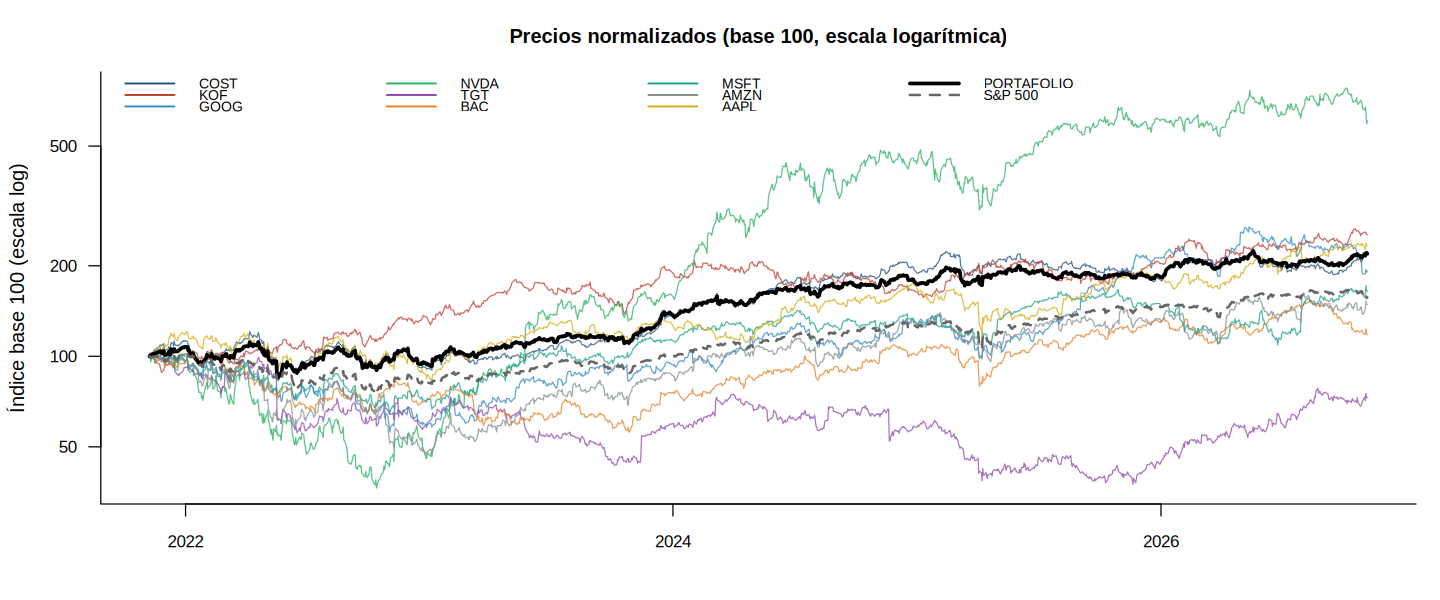

In [5]:
seccion("2. Portafolio en HowTheMarketWorks")
acc    <- setNames(PORTAFOLIO$acciones, TICKERS)
pagado <- setNames(PORTAFOLIO$precio_pagado, TICKERS)
ultimo <- precios[nrow(precios), ]
valor  <- acc * ultimo
pesos  <- valor / sum(valor)
VALOR_TOTAL <- sum(valor); COSTO_TOTAL <- sum(acc * pagado)

comp <- data.frame(Empresa = PORTAFOLIO$empresa, Acciones = acc, `Precio pagado` = pagado, `Último precio` = ultimo,
                   `Valor de mercado` = valor, `Peso %` = pesos * 100, `Ganancia/Pérdida` = valor - acc * pagado,
                   `Rend. %` = (ultimo / pagado - 1) * 100, check.names = FALSE, stringsAsFactors = FALSE, row.names = TICKERS)
comp <- rbind(comp, data.frame(Empresa = "Total", Acciones = NA, `Precio pagado` = NA, `Último precio` = NA,
                               `Valor de mercado` = VALOR_TOTAL, `Peso %` = 100, `Ganancia/Pérdida` = VALOR_TOTAL - COSTO_TOTAL,
                               `Rend. %` = (VALOR_TOTAL / COSTO_TOTAL - 1) * 100, check.names = FALSE, row.names = "TOTAL"))
tabla(comp, paste0("Composición del portafolio al ", tail(dias, 1)), 2, "Ticker")
texto(sprintf("El portafolio vale $%s y acumula una %s de $%s (%s%%) sobre un costo de $%s. Está concentrado en %s (%.1f%%) y %s (%.1f%%), lo que hace que su riesgo dependa principalmente de esas dos emisoras.",
              f2(VALOR_TOTAL), ifelse(VALOR_TOTAL >= COSTO_TOTAL, "ganancia", "pérdida"), f2(abs(VALOR_TOTAL - COSTO_TOTAL)),
              f2((VALOR_TOTAL / COSTO_TOTAL - 1) * 100), f2(COSTO_TOTAL),
              names(sort(pesos, decreasing = TRUE))[1], sort(pesos, decreasing = TRUE)[1] * 100,
              names(sort(pesos, decreasing = TRUE))[2], sort(pesos, decreasing = TRUE)[2] * 100))

tabla(data.frame(Valor = CUENTA_HTMW), "Resumen de la cuenta en HowTheMarketWorks (Account Balances)", 2, "Concepto")
texto(sprintf("La cuenta del concurso rinde %.2f%% frente a %.2f%% del SPY en el mismo periodo: %.2f puntos porcentuales por encima del mercado. El %.1f%% de la cuenta permanece en efectivo, lo que reduce la exposición al riesgo de mercado y explica parte del mejor desempeño relativo en un periodo de baja.",
              CUENTA_HTMW[["Rendimiento de la cuenta %"]], CUENTA_HTMW[["Rendimiento del SPY en el mismo periodo %"]],
              CUENTA_HTMW[["Rendimiento de la cuenta %"]] - CUENTA_HTMW[["Rendimiento del SPY en el mismo periodo %"]],
              CUENTA_HTMW[["Efectivo disponible"]] / CUENTA_HTMW[["Valor total de la cuenta"]] * 100))

port_val <- setNames(as.numeric(precios %*% acc), dias)
R   <- diff(log(precios))
rp  <- diff(log(port_val))
rmk <- diff(log(FACT[, BENCH]))

asimetria <- function(x) mean((x - mean(x))^3) / sd(x)^3
curtosis  <- function(x) mean((x - mean(x))^4) / sd(x)^4 - 3
descr <- function(x) c(`Rend. anual %` = mean(x) * 252 * 100, `Vol. anual %` = sd(x) * sqrt(252) * 100,
                       Sharpe = (mean(x) * 252 - RF) / (sd(x) * sqrt(252)), Asimetría = asimetria(x),
                       `Curtosis exceso` = curtosis(x), `p Jarque-Bera` = tseries::jarque.bera.test(x)$p.value)
desc <- rbind(t(apply(R, 2, descr)), PORTAFOLIO = descr(rp), `S&P 500` = descr(rmk))
tabla(desc, "Estadística descriptiva de los rendimientos logarítmicos diarios", 3, "Activo")
texto("Todos los p-valores de Jarque-Bera son prácticamente cero: los rendimientos no son normales, presentan colas pesadas (curtosis en exceso positiva). Por eso se usan errores estándar robustos en las regresiones y una distribución t-Student en los modelos GARCH.")

figura("Desempeño histórico (base 100): acciones, portafolio y S&P 500", function() {
  estilo()
  b100 <- sweep(precios, 2, precios[1, ], "/") * 100
  p100 <- port_val / port_val[1] * 100; m100 <- FACT[, BENCH] / FACT[1, BENCH] * 100
  plot(fechas, p100, type = "n", ylim = range(b100, p100, m100), xlab = "", ylab = "Índice base 100 (escala log)",
       main = "Precios normalizados (base 100, escala logarítmica)", log = "y")
  matlines(fechas, b100, lty = 1, lwd = 1, col = adjustcolor(COL[seq_along(TICKERS)], 0.75))
  lines(fechas, p100, lwd = 3, col = "black"); lines(fechas, m100, lwd = 2, lty = 2, col = "gray40")
  legend("topleft", c(TICKERS, "PORTAFOLIO", "S&P 500"), col = c(COL[seq_along(TICKERS)], "black", "gray40"),
         lty = c(rep(1, length(TICKERS)), 1, 2), lwd = c(rep(1.5, length(TICKERS)), 3, 2), ncol = 4, cex = 0.7, bty = "n")
})

## 3. Regresión lineal simple: modelo de mercado (CAPM)
$r_{i,t} = \alpha_i + \beta_i r_{m,t} + u_{i,t}$. Errores estándar robustos a heteroscedasticidad (HC1); pruebas de Durbin-Watson (autocorrelación), Breusch-Pagan (heteroscedasticidad) y Jarque-Bera (normalidad de los residuos).


3. Regresión lineal simple: CAPM

Tabla 5. CAPM con rendimientos diarios (2021-2026)
     Activo Alfa anual %  Beta t Beta (HC1) p Beta    R2 Durbin-Watson
       COST        9.867 0.667       13.328      0 0.244         1.919
        KOF       14.483 0.465       10.839      0 0.104         2.082
       GOOG        1.740 1.255       28.712      0 0.438         1.918
       NVDA       16.761 2.158       33.975      0 0.515         2.090
        TGT      -14.685 0.926        9.965      0 0.183         1.997
        BAC       -5.396 0.963       20.347      0 0.382         1.862
       MSFT       -0.444 1.148       30.825      0 0.483         1.980
       AMZN       -5.715 1.511       25.606      0 0.499         1.950
       AAPL        6.500 1.160       26.726      0 0.501         1.814
 PORTAFOLIO        9.400 0.705       19.269      0 0.425         1.902
 p Breusch-Pagan p Jarque-Bera    N
           0.000             0 1254
           0.354             0 1254
           0.542         

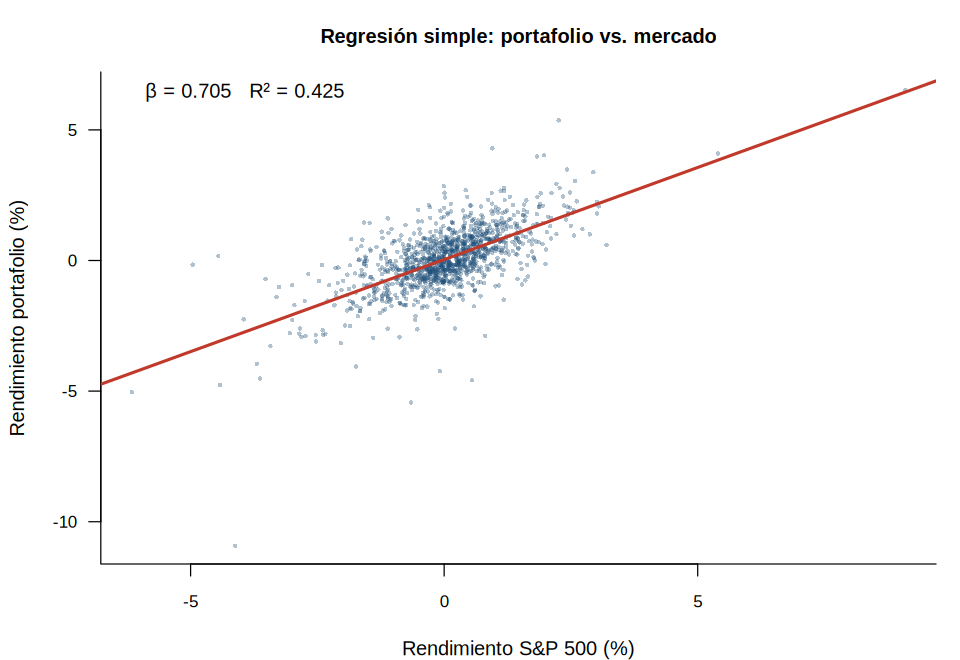

En la mayoría de las acciones los R² con datos de 5 y 1 minuto son mucho menores que con datos diarios y
varias betas disminuyen. Es el efecto Epps: a muy alta frecuencia la negociación no sincrónica y el ruido de
microestructura atenúan la covarianza con el mercado; el ADR de KOF, menos líquido, es un ejemplo claro. Las
acciones más líquidas (NVDA, MSFT, AMZN, GOOG) conservan betas similares en todas las frecuencias.



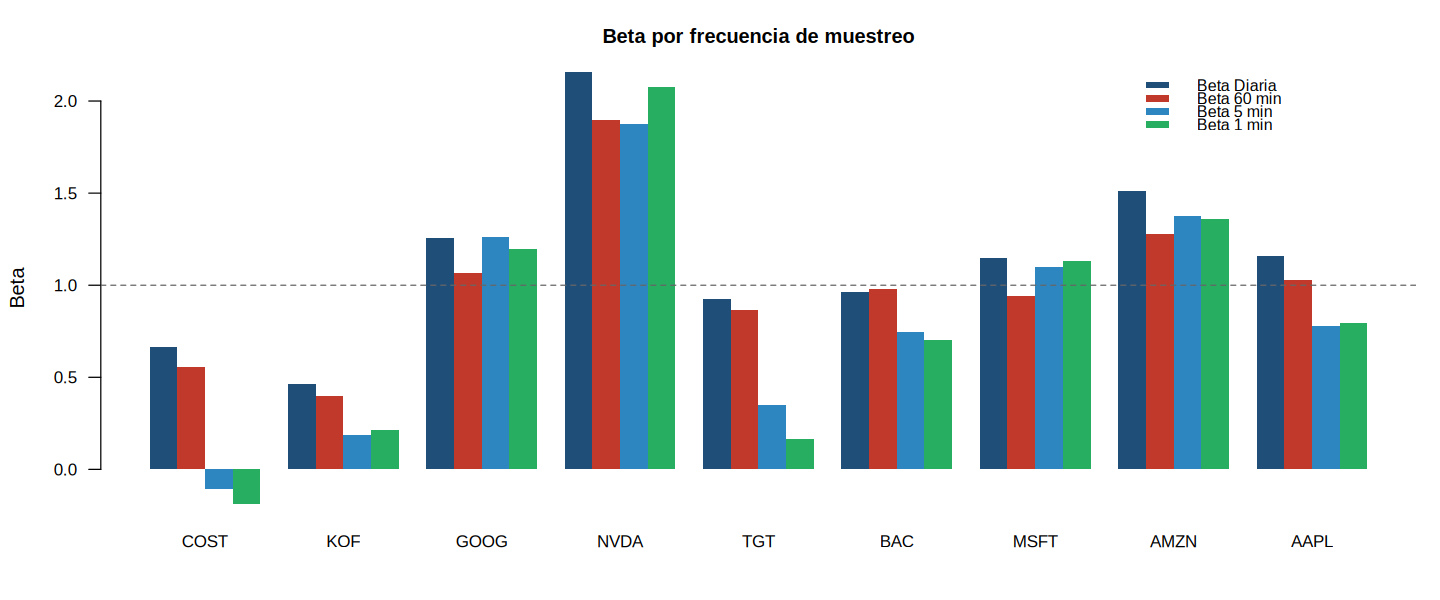

La beta no es constante en el tiempo. En los últimos seis meses la beta de COST es -0.39 (correlación con el
S&P 500 de -0.25), frente a 0.67 en toda la muestra, y la del portafolio bajó a 0.00. Como los datos de 5 y 1
minuto cubren solo ese periodo reciente, las betas intradía negativas de COST reflejan este cambio de régimen
(Costco se movió en sentido contrario al mercado) y no un error en los datos.



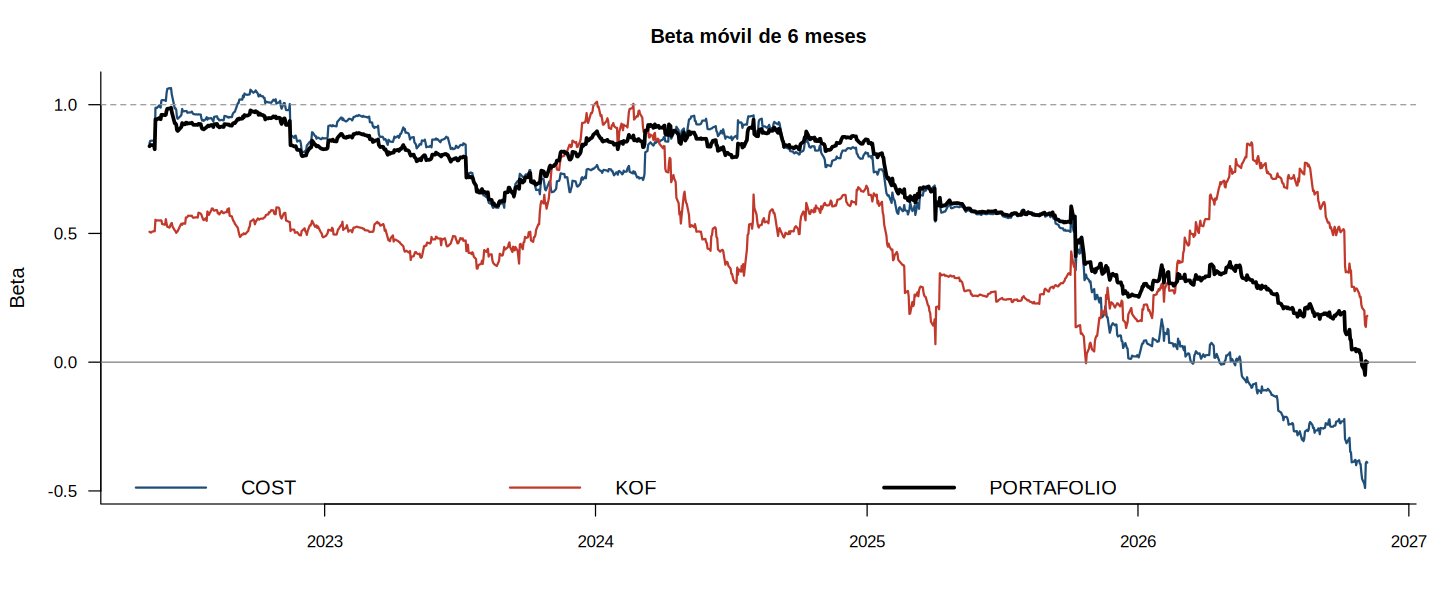

In [6]:
seccion("3. Regresión lineal simple: CAPM")
capm_fila <- function(y, x) {
  ok <- is.finite(y) & is.finite(x); y <- y[ok]; x <- x[ok]
  m <- lm(y ~ x); ct <- p_robusto(m)
  c(`Alfa anual %` = unname(coef(m)[1]) * 252 * 100, Beta = unname(coef(m)[2]), `t Beta (HC1)` = ct[2, 3],
    `p Beta` = ct[2, 4], R2 = summary(m)$r.squared, `Durbin-Watson` = unname(lmtest::dwtest(m)$statistic),
    `p Breusch-Pagan` = unname(lmtest::bptest(m)$p.value),
    `p Jarque-Bera` = unname(tseries::jarque.bera.test(residuals(m))$p.value), N = length(y))
}
capm <- rbind(t(sapply(TICKERS, function(tk) capm_fila(R[, tk], rmk))), PORTAFOLIO = capm_fila(rp, rmk))
tabla(capm, "CAPM con rendimientos diarios (2021-2026)", 3, "Activo")

m_capm <- lm(rp ~ rmk)
print(summary(m_capm)); print(p_robusto(m_capm))
bmax <- names(which.max(capm[TICKERS, "Beta"])); bmin <- names(which.min(capm[TICKERS, "Beta"]))
texto(sprintf("La beta del portafolio es %.3f (R² = %.3f): por cada 1%% que se mueve el S&P 500, el portafolio se mueve en promedio %.2f%%. La acción más agresiva es %s (β = %.2f) y la más defensiva %s (β = %.2f). Los p-valores de Breusch-Pagan bajos indican heteroscedasticidad, por lo que la inferencia se basa en errores robustos HC1; el estadístico Durbin-Watson cercano a 2 indica ausencia de autocorrelación de primer orden.",
              capm["PORTAFOLIO", "Beta"], capm["PORTAFOLIO", "R2"], capm["PORTAFOLIO", "Beta"], bmax, capm[bmax, "Beta"], bmin, capm[bmin, "Beta"]))
figura("Línea característica del portafolio (rendimientos diarios)", function() {
  estilo()
  plot(rmk * 100, rp * 100, pch = 16, cex = 0.5, col = adjustcolor(COL[1], 0.35),
       xlab = "Rendimiento S&P 500 (%)", ylab = "Rendimiento portafolio (%)", main = "Regresión simple: portafolio vs. mercado")
  abline(lm(I(rp * 100) ~ I(rmk * 100)), col = COL[2], lwd = 2.5)
  legend("topleft", sprintf("β = %.3f   R² = %.3f", coef(m_capm)[2], summary(m_capm)$r.squared), bty = "n")
}, 8, 5.5)

# Betas por frecuencia: diario, 60, 5 y 1 minuto
ret_intra <- function(I) {
  L <- log(I$P); Rr <- rbind(NA, diff(L)); rownames(Rr) <- rownames(L)
  Rr[c(TRUE, I$dia[-1] != I$dia[-length(I$dia)]), ] <- NA
  Rr
}
R60 <- ret_intra(I60); R5 <- ret_intra(I5); R1 <- ret_intra(I1)
beta_r2 <- function(y, x) { ok <- is.finite(y) & is.finite(x); if (sum(ok) < 30) return(c(NA, NA)); m <- lm(y[ok] ~ x[ok]); c(unname(coef(m)[2]), summary(m)$r.squared) }
frecs <- list(Diaria = list(R = R, m = rmk), `60 min` = list(R = R60, m = R60[, BENCH_ID]),
              `5 min` = list(R = R5, m = R5[, BENCH_ID]), `1 min` = list(R = R1, m = R1[, BENCH_ID]))
BR <- lapply(frecs, function(f) t(sapply(TICKERS, function(tk) beta_r2(f$R[, tk], f$m))))
betas_frec <- sapply(BR, function(b) b[, 1]); r2_frec <- sapply(BR, function(b) b[, 2])
colnames(betas_frec) <- paste("Beta", colnames(betas_frec)); colnames(r2_frec) <- paste("R2", colnames(r2_frec))
tabla(cbind(betas_frec, r2_frec), "CAPM por frecuencia de muestreo: diaria, horas y minutos", 3, "Acción")
figura("Betas estimadas con datos diarios, por hora y por minuto", function() {
  estilo()
  barplot(t(betas_frec), beside = TRUE, col = COL[1:4], border = NA, ylab = "Beta", main = "Beta por frecuencia de muestreo")
  abline(h = 1, lty = 2, col = "gray40")
  legend("topright", colnames(betas_frec), fill = COL[1:4], border = NA, bty = "n", cex = 0.8)
})
texto("En la mayoría de las acciones los R² con datos de 5 y 1 minuto son mucho menores que con datos diarios y varias betas disminuyen. Es el efecto Epps: a muy alta frecuencia la negociación no sincrónica y el ruido de microestructura atenúan la covarianza con el mercado; el ADR de KOF, menos líquido, es un ejemplo claro. Las acciones más líquidas (NVDA, MSFT, AMZN, GOOG) conservan betas similares en todas las frecuencias.")
VENT <- 126
beta_movil <- function(y) sapply(VENT:length(rmk), function(i) { k <- (i - VENT + 1):i; cov(y[k], rmk[k]) / var(rmk[k]) })
roll <- cbind(COST = beta_movil(R[, "COST"]), KOF = beta_movil(R[, "KOF"]), PORTAFOLIO = beta_movil(rp))
f_roll <- fechas[-1][VENT:length(rmk)]
figura("Beta móvil de 126 días (6 meses) frente al S&P 500", function() {
  estilo()
  matplot(f_roll, roll, type = "l", lty = 1, lwd = c(1.8, 1.8, 3), col = c(COL[1], COL[2], "black"), xlab = "", ylab = "Beta", main = "Beta móvil de 6 meses", xaxt = "n")
  axis.Date(1, f_roll); abline(h = 0, col = "gray50"); abline(h = 1, lty = 2, col = "gray60")
  legend("bottomleft", colnames(roll), col = c(COL[1], COL[2], "black"), lwd = c(1.8, 1.8, 3), bty = "n", horiz = TRUE)
})
texto(sprintf("La beta no es constante en el tiempo. En los últimos seis meses la beta de COST es %.2f (correlación con el S&P 500 de %.2f), frente a %.2f en toda la muestra, y la del portafolio bajó a %.2f. Como los datos de 5 y 1 minuto cubren solo ese periodo reciente, las betas intradía negativas de COST reflejan este cambio de régimen (Costco se movió en sentido contrario al mercado) y no un error en los datos.",
              (round(tail(roll[, "COST"], 1), 2) + 0), cor(tail(R[, "COST"], VENT), tail(rmk, VENT)), capm["COST", "Beta"], (round(tail(roll[, "PORTAFOLIO"], 1), 2) + 0)))

## 4. Regresión lineal múltiple y horas seleccionadas
$r_{i,t} = \beta_0 + \beta_1 r_{m,t} + \beta_2 \Delta \ln VIX_t + \beta_3 \Delta Tasa10Y_t + \beta_4 r_{USD/MXN,t} + \beta_5 r_{WTI,t} + u_t$, con diagnóstico de multicolinealidad (VIF). Después, regresión con variables dicótomas por hora del día.


4. Regresión lineal múltiple

Tabla 7. Regresión múltiple con factores (diario; p-valores robustos HC1)
     Activo β Mercado p Mercado  β VIX p VIX β Tasa10Y p Tasa10Y β USDMXN
       COST     0.826         0  0.029 0.001    -0.007     0.261    0.032
        KOF     0.405         0 -0.009 0.321    -0.026     0.000   -0.076
       GOOG     1.392         0  0.024 0.007     0.005     0.523   -0.033
       NVDA     2.233         0  0.012 0.400     0.026     0.029   -0.008
        TGT     1.009         0  0.017 0.173    -0.018     0.126   -0.062
        BAC     0.874         0 -0.017 0.030     0.022     0.003   -0.085
       MSFT     1.279         0  0.023 0.006     0.012     0.036    0.010
       AMZN     1.581         0  0.012 0.262     0.004     0.693   -0.021
       AAPL     1.268         0  0.019 0.018     0.000     0.977    0.049
 PORTAFOLIO     0.793         0  0.016 0.006    -0.009     0.033   -0.001
 p USDMXN β Petroleo p Petroleo R2 aj. p F    DW    N
    0.534     -0.001      0

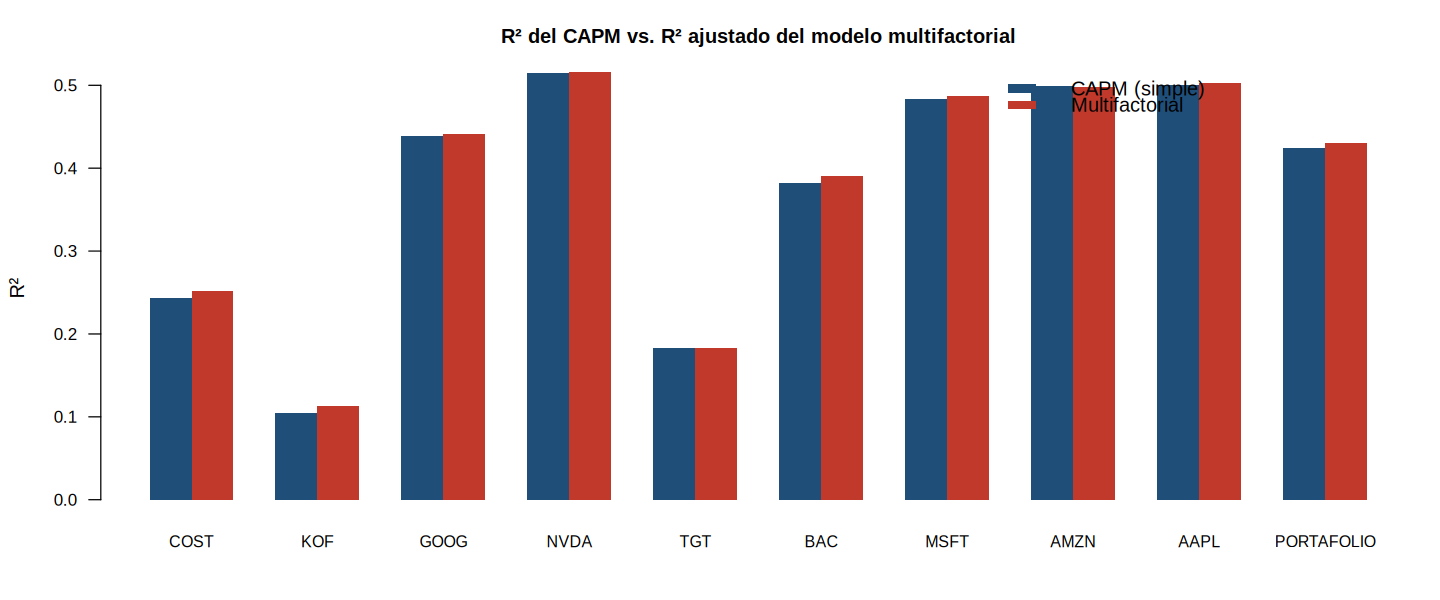

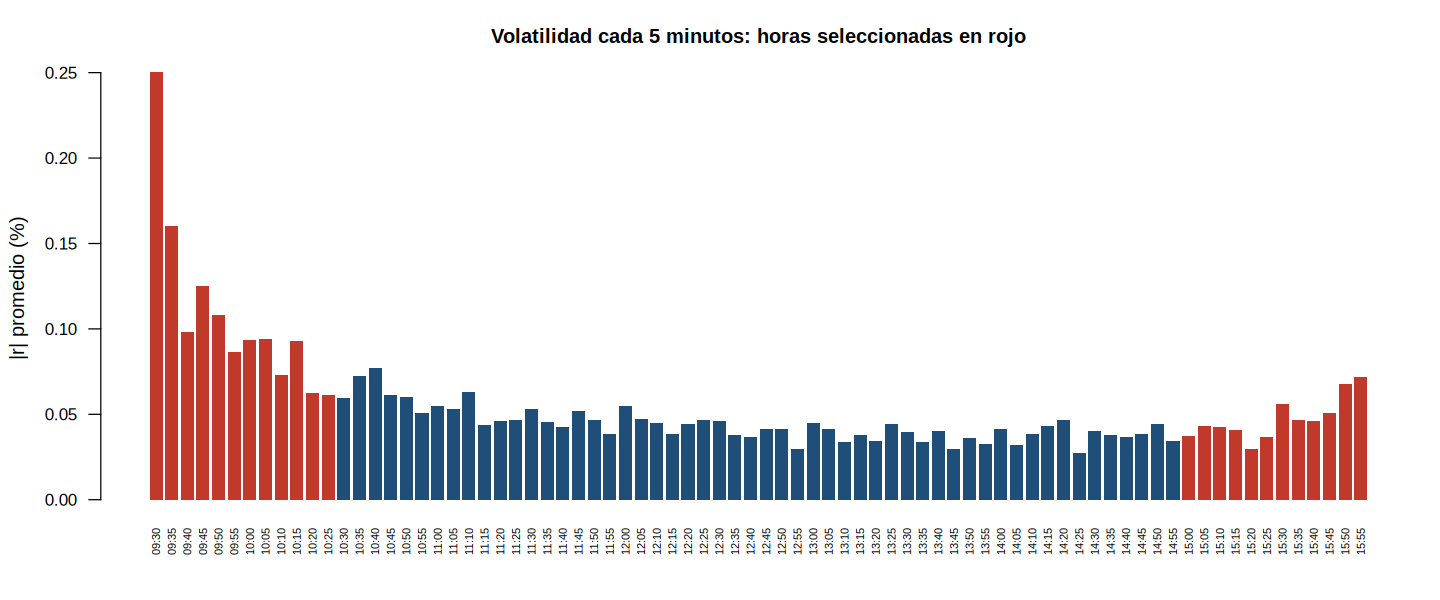

In [7]:
seccion("4. Regresión lineal múltiple")
FAC <- as.data.frame(sapply(names(FACTORES), function(k) {
  x <- FACT[, FACTORES[[k]]]
  if (grepl("Tasa", k)) diff(x) else diff(log(x))
}))
FAC[!sapply(FAC, is.finite)] <- NA

mult_fila <- function(y) {
  m <- lm(y ~ ., data = data.frame(y = y, FAC)); ct <- p_robusto(m); s <- summary(m)
  out <- c()
  for (k in names(FACTORES)) out <- c(out, setNames(c(coef(m)[k], ct[k, 4]), c(paste("β", k), paste("p", k))))
  c(out, `R2 aj.` = s$adj.r.squared,
    `p F` = unname(pf(s$fstatistic[1], s$fstatistic[2], s$fstatistic[3], lower.tail = FALSE)),
    DW = unname(lmtest::dwtest(m)$statistic), N = nobs(m))
}
multiple <- rbind(t(sapply(TICKERS, function(tk) mult_fila(R[, tk]))), PORTAFOLIO = mult_fila(rp))
tabla(multiple, "Regresión múltiple con factores (diario; p-valores robustos HC1)", 3, "Activo")

m_mult <- lm(y ~ ., data = data.frame(y = rp, FAC))
print(summary(m_mult)); print(p_robusto(m_mult))
vif_tab <- data.frame(VIF = car::vif(m_mult))
tabla(vif_tab, "Factor de inflación de varianza del modelo del portafolio (VIF > 10 = multicolinealidad grave)", 2, "Variable")
sig <- names(FACTORES)[multiple["PORTAFOLIO", paste("p", names(FACTORES))] < 0.05]
texto(sprintf("Al pasar del CAPM al modelo multifactorial, el R² ajustado promedio de las acciones pasa de %.3f a %.3f%s. En el portafolio son significativos al 5%%: %s. El VIF máximo es %.2f, por lo que no hay multicolinealidad relevante.",
              mean(capm[TICKERS, "R2"]), mean(multiple[TICKERS, "R2 aj."]),
              ifelse(mean(multiple[TICKERS, "R2 aj."]) - mean(capm[TICKERS, "R2"]) < 0.02, ", una mejora marginal: aunque algunos factores son estadísticamente significativos, el mercado concentra casi todo el poder explicativo", ""),
              ifelse(length(sig) > 0, paste(sig, collapse = ", "), "ningún factor"), max(vif_tab$VIF)))
figura("Poder explicativo: regresión simple vs. múltiple", function() {
  estilo()
  barplot(rbind(capm[, "R2"], multiple[, "R2 aj."]), beside = TRUE, col = COL[c(1, 2)], border = NA,
          ylab = "R²", main = "R² del CAPM vs. R² ajustado del modelo multifactorial", cex.names = 0.8)
  legend("topright", c("CAPM (simple)", "Multifactorial"), fill = COL[c(1, 2)], border = NA, bty = "n")
})

seccion("4.1 Horas seleccionadas: variables dicótomas intradía", 3)
port_intra <- function(Rr) {
  M <- Rr[, TICKERS]; ok <- rowSums(!is.na(M)) > 0
  M[is.na(M)] <- 0
  list(r = as.numeric(M %*% pesos[TICKERS])[ok], ok = ok)
}
ret_barra <- function(I) { Rr <- log(I$P / I$O); Rr[!is.finite(Rr)] <- NA; Rr }
p60 <- port_intra(ret_barra(I60))
intervalo <- function(h, min) { fin <- format(as.POSIXct(paste("2000-01-01", h), tz = "UTC") + min * 60, "%H:%M"); paste0(h, "-", ifelse(fin > "16:00", "16:00", fin)) }
dh <- data.frame(abs_r = abs(p60$r) * 100, hora = I60$hora[p60$ok])
dh <- dh[dh$hora %in% names(which(table(dh$hora) >= 50)), ]
dh$hora <- relevel(factor(dh$hora), ref = if ("12:30" %in% dh$hora) "12:30" else levels(factor(dh$hora))[1])
m_hora <- lm(abs_r ~ hora, data = dh); ct_h <- p_robusto(m_hora)
tab_h <- data.frame(Coeficiente = ct_h[, 1], `p (HC1)` = ct_h[, 4], check.names = FALSE)
rownames(tab_h) <- c(paste0("Constante (", intervalo(levels(dh$hora)[1], 60), ")"), intervalo(sub("^hora", "", rownames(tab_h)[-1]), 60))
tabla(tab_h, "|Rendimiento| de cada hora del portafolio (%) con variables dicótomas de hora (base: hora del mediodía)", 4, "Hora")

p5 <- port_intra(ret_barra(I5))
hora5 <- I5$hora[p5$ok]
d5 <- data.frame(abs_r = abs(p5$r) * 100, apertura = as.integer(hora5 < "10:30"), cierre = as.integer(hora5 >= "15:00"))
m_sel <- lm(abs_r ~ apertura + cierre, data = d5); ct_s <- p_robusto(m_sel)
tabla(data.frame(Coeficiente = ct_s[, 1], `p (HC1)` = ct_s[, 4], check.names = FALSE, row.names = c("Constante (resto del día)", "Apertura 9:30-10:30", "Cierre 15:00-16:00")),
      "|Rendimiento| de 5 minutos: horas seleccionadas (apertura y cierre)", 4, "Variable")
CIERRE_SIG <- ct_s["cierre", 4] < 0.05
texto(sprintf("En la primera hora de operación el movimiento absoluto promedio cada 5 minutos es %.4f puntos porcentuales mayor que en el resto del día (p = %.4f), es decir, %.1f veces el nivel del mediodía. En la última hora la diferencia es %.4f (p = %.4f)%s",
              coef(m_sel)["apertura"], ct_s["apertura", 4], (coef(m_sel)[1] + coef(m_sel)["apertura"]) / coef(m_sel)[1], coef(m_sel)["cierre"], ct_s["cierre", 4],
              if (CIERRE_SIG) ": la volatilidad forma una U, alta en la apertura y en el cierre." else
              ", no significativa en promedio: el efecto dominante es la apertura, cuando se incorpora la información acumulada durante la noche; el repunte del cierre se limita a los últimos 15-20 minutos de la sesión."))
perfil <- tapply(d5$abs_r, hora5, mean)
figura("Patrón intradía de volatilidad del portafolio (|rendimiento| promedio cada 5 minutos)", function() {
  estilo()
  cols <- ifelse(names(perfil) < "10:30" | names(perfil) >= "15:00", COL[2], COL[1])
  barplot(perfil, col = cols, border = NA, las = 2, cex.names = 0.55, ylab = "|r| promedio (%)",
          main = "Volatilidad cada 5 minutos: horas seleccionadas en rojo")
})

## 5. Datos panel: reportes trimestrales
Panel empresa-trimestre. Variable dependiente: rendimiento logarítmico trimestral de la acción. Regresoras: crecimiento de ingresos, margen neto, ROE y apalancamiento (pasivo/activo). Se estiman MCO agrupado, efectos fijos y efectos aleatorios; la elección se hace con las pruebas F, Breusch-Pagan (LM) y Hausman.


5. Datos panel con reportes trimestrales

Tabla 11. Base de datos panel (empresa-trimestre)
 ticker trimestre      fecha crec_ingresos margen_neto    roe apalancamiento
   AAPL   2025-T4 2025-12-31        0.4030      0.2928 0.4773         0.7675
   AAPL   2026-T1 2026-03-31       -0.2266      0.2660 0.2778         0.7130
   AAPL   2026-T2 2026-06-30       -0.0159      0.2723 0.2771         0.7195
   AAPL   2026-T3 2026-09-30        0.0462      0.2683 0.2740         0.7229
   AMZN   2025-T3 2025-09-30        0.0743      0.1176 0.0573         0.4922
   AMZN   2025-T4 2025-12-31        0.1844      0.0993 0.0516         0.4975
   AMZN   2026-T1 2026-03-31       -0.1493      0.1667 0.0685         0.5179
    BAC   2025-T3 2025-09-30        0.0582      0.2869 0.0274         0.9106
    BAC   2025-T4 2025-12-31        0.0737      0.2414 0.0248         0.9111
    BAC   2026-T1 2026-03-31       -0.0291      0.2836 0.0285         0.9140
   COST   2025-T4 2025-11-30       -0.2188      0.0297 0.066

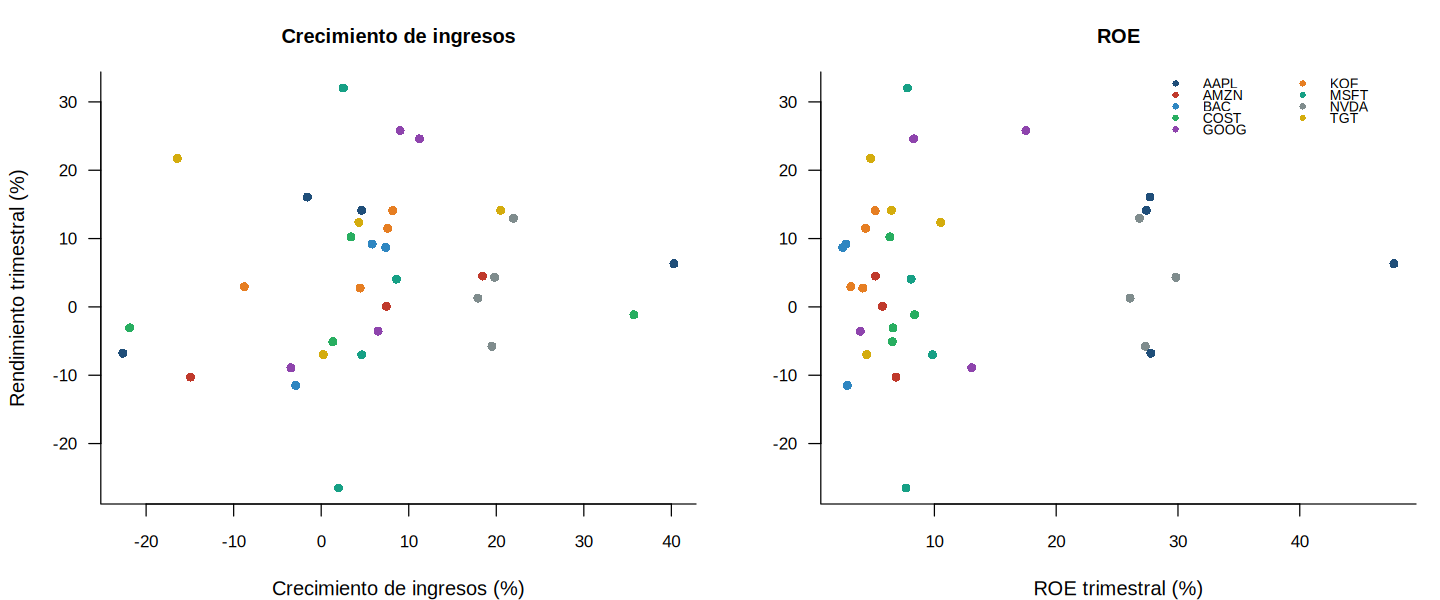

In [8]:
seccion("5. Datos panel con reportes trimestrales")
PANEL_OK <- FALSE
VARS_P <- c("crec_ingresos", "margen_neto", "roe", "apalancamiento")
tryCatch({
  T0 <- read.csv("datos/trimestral.csv", stringsAsFactors = FALSE)
  W <- tapply(T0$valor, list(paste(T0$ticker, T0$fecha, sep = "|"), T0$partida), function(v) tail(v, 1))
  W <- as.data.frame(W)
  W$ticker <- sub("\\|.*$", "", rownames(W)); W$fecha <- as.Date(sub("^.*\\|", "", rownames(W)))
  W <- W[order(W$ticker, W$fecha), ]
  W$crec_ingresos  <- ave(W$TotalRevenue, W$ticker, FUN = function(v) c(NA, v[-1] / v[-length(v)] - 1))
  W$margen_neto    <- W$NetIncome / W$TotalRevenue
  W$roe            <- W$NetIncome / W$StockholdersEquity
  W$apalancamiento <- 1 - W$StockholdersEquity / W$TotalAssets
  precio_en <- function(tk, f) { i <- findInterval(as.numeric(f), as.numeric(fechas)); if (i < 1) NA else precios[i, tk] }
  W$rend_trim <- mapply(function(tk, fs) {
    f <- as.Date(fs); f0 <- seq(f, by = "-3 months", length.out = 2)[2]
    log(precio_en(tk, f) / precio_en(tk, f0))
  }, W$ticker, as.character(W$fecha), USE.NAMES = FALSE)
  W$trimestre <- paste0(format(W$fecha, "%Y"), "-T", (as.integer(format(W$fecha, "%m")) - 1) %/% 3 + 1)
  panel <- W[complete.cases(W[, c(VARS_P, "rend_trim")]), c("ticker", "trimestre", "fecha", VARS_P, "rend_trim")]
  panel <- panel[!duplicated(panel[, c("ticker", "trimestre")], fromLast = TRUE), ]
  rownames(panel) <- NULL
  tabla(panel, "Base de datos panel (empresa-trimestre)", 4)
  texto(sprintf("Panel %s con %d empresas y %d observaciones (trimestres fiscales homologados a trimestre calendario). KOF reporta en pesos mexicanos; como todas las regresoras son razones financieras, la moneda no afecta la comparación.",
                ifelse(length(unique(table(panel$ticker))) == 1, "balanceado", "no balanceado"), length(unique(panel$ticker)), nrow(panel)))

  pdat <- plm::pdata.frame(panel[, c("ticker", "trimestre", VARS_P, "rend_trim")], index = c("ticker", "trimestre"))
  fml  <- rend_trim ~ crec_ingresos + margen_neto + roe + apalancamiento
  pool <- plm::plm(fml, data = pdat, model = "pooling")
  fe   <- plm::plm(fml, data = pdat, model = "within")
  re   <- tryCatch(plm::plm(fml, data = pdat, model = "random"),
                   error = function(e) plm::plm(fml, data = pdat, model = "random", random.method = "amemiya"))
  print(summary(fe)); print(summary(re))
  rob <- function(m) lmtest::coeftest(m, vcov. = sandwich::vcovHC(m, method = "arellano", type = "HC1", cluster = "group"))
  ct_pool <- rob(pool); ct_fe <- rob(fe); ct_re <- lmtest::coeftest(re)
  vv <- c("(Intercept)", VARS_P)
  toma <- function(ct, j) sapply(vv, function(v) if (v %in% rownames(ct)) ct[v, j] else NA)
  comp_p <- data.frame(`MCO agrupado β` = toma(ct_pool, 1), `MCO agrupado p` = toma(ct_pool, 4),
                       `Efectos fijos β` = toma(ct_fe, 1), `Efectos fijos p` = toma(ct_fe, 4),
                       `Efectos aleatorios β` = toma(ct_re, 1), `Efectos aleatorios p` = toma(ct_re, 4),
                       check.names = FALSE, row.names = vv)
  tabla(comp_p, "Estimaciones panel (errores agrupados por empresa en MCO agrupado y efectos fijos)", 4, "Variable")
  r2 <- function(m) unname(summary(m)$r.squared[1])
  tabla(data.frame(R2 = c(r2(pool), r2(fe), r2(re)), row.names = c("MCO agrupado", "Efectos fijos", "Efectos aleatorios")),
        "Bondad de ajuste", 3, "Modelo")
  pF <- plm::pFtest(fe, pool); bpl <- plm::plmtest(pool, type = "bp"); hs <- plm::phtest(fe, re)
  pruebas <- data.frame(Estadístico = c(unname(pF$statistic), unname(bpl$statistic), unname(hs$statistic)),
                        `p-valor` = c(pF$p.value, bpl$p.value, hs$p.value),
                        Contraste = c("Efectos fijos vs. MCO agrupado", "Efectos aleatorios vs. MCO agrupado", "Efectos fijos vs. efectos aleatorios"),
                        check.names = FALSE, row.names = c("F de efectos individuales", "Breusch-Pagan LM", "Hausman"))
  tabla(pruebas, "Pruebas de especificación del panel", 4, "Prueba")
  ELEGIDO_PANEL <- if (hs$p.value < 0.05) "efectos fijos" else if (bpl$p.value < 0.05) "efectos aleatorios" else if (pF$p.value < 0.05) "efectos fijos" else "MCO agrupado"
  P_HAUSMAN <- hs$p.value
  if (max(abs(coef(re) - coef(pool)[names(coef(re))])) < 1e-6)
    texto("La varianza estimada del efecto individual es cero, por lo que el estimador de efectos aleatorios coincide con el de MCO agrupado: las diferencias entre empresas no agregan información una vez que se controla por los fundamentales.")
  texto(sprintf("Hausman p = %.4f, F de efectos p = %.4f y Breusch-Pagan LM p = %.4f: el modelo preferido es **%s**. Con solo cinco trimestres por empresa, los coeficientes deben leerse como evidencia exploratoria; un panel más largo (por ejemplo, exportado de Bloomberg o Refinitiv) daría estimaciones más precisas.",
                hs$p.value, pF$p.value, bpl$p.value, ELEGIDO_PANEL))
  figura("Fundamentales trimestrales vs. rendimiento trimestral de la acción", function() {
    par(mfrow = c(1, 2)); estilo()
    cl <- COL[as.integer(factor(panel$ticker))]
    plot(panel$crec_ingresos * 100, panel$rend_trim * 100, pch = 16, col = cl, xlab = "Crecimiento de ingresos (%)", ylab = "Rendimiento trimestral (%)", main = "Crecimiento de ingresos")
    plot(panel$roe * 100, panel$rend_trim * 100, pch = 16, col = cl, xlab = "ROE trimestral (%)", ylab = "", main = "ROE")
    legend("topright", levels(factor(panel$ticker)), col = COL, pch = 16, cex = 0.7, bty = "n", ncol = 2)
  })
  PANEL_OK <- TRUE
}, error = function(e) texto(paste("No fue posible estimar el panel:", conditionMessage(e))))

## 6. Series de tiempo: metodología Box-Jenkins (AR, MA, ARMA, ARIMA)
1. **Estacionariedad**: pruebas ADF y KPSS (orden de integración *d*).
2. **Descomposición y periodicidad**: STL, transformada de Fourier y exponente de Hurst (*Python Time Series Handbook*, F. M. Bianchi).
3. **Identificación**: funciones de autocorrelación simple (ACF) y parcial (PACF).
4. **Estimación** de modelos AR(p), MA(q), ARMA(p,q) y ARIMA(p,d,q); selección por AIC/BIC.
5. **Diagnóstico**: residuos como ruido blanco (Ljung-Box).
6. **Pronóstico** (forecast) diario, por hora y por minuto, validado fuera de muestra contra el paseo aleatorio.


6. Series de tiempo: metodología Box-Jenkins

6.1 Estacionariedad

Tabla 15. Pruebas de raíz unitaria (ADF: H0 raíz unitaria; KPSS: H0 estacionariedad)
      Serie ADF nivel p ADF rend. p KPSS nivel p KPSS rend. p d sugerida
       COST      0.4451        0.01         0.01          0.1          1
        KOF      0.3299        0.01         0.01          0.1          1
       GOOG      0.2827        0.01         0.01          0.1          1
       NVDA      0.5170        0.01         0.01          0.1          1
        TGT      0.6790        0.01         0.01          0.1          1
        BAC      0.2609        0.01         0.01          0.1          1
       MSFT      0.2919        0.01         0.01          0.1          1
       AMZN      0.1100        0.01         0.01          0.1          1
       AAPL      0.2362        0.01         0.01          0.1          1
 PORTAFOLIO      0.2521        0.01         0.01          0.1          1
                     Conclusión
 I(1): raíz 

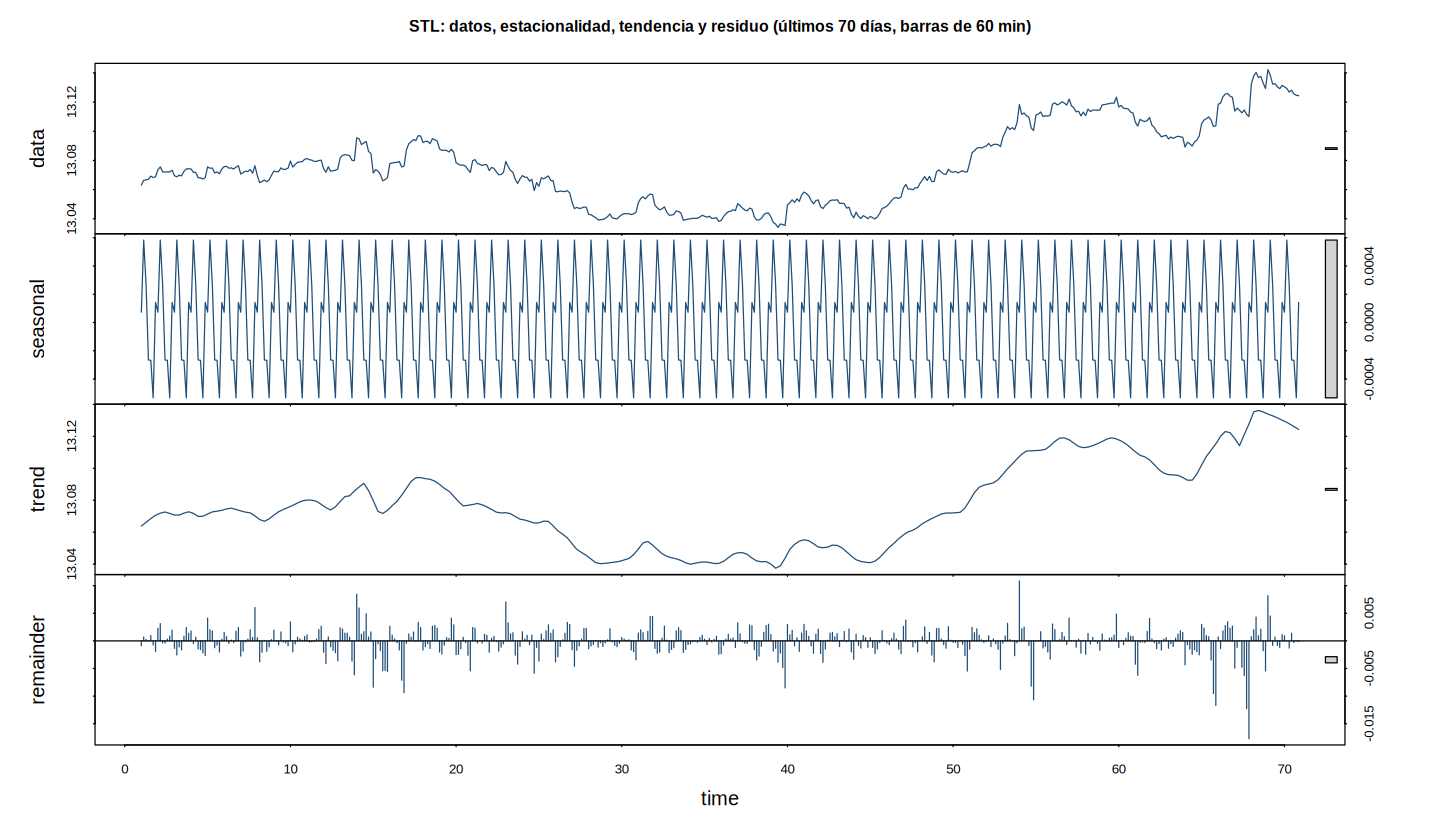

La descomposición STL muestra una estacionalidad intradía débil frente a la tendencia (fuerza de
estacionalidad = 0.03) en el nivel de precios. La transformada de Fourier aplicada a la volatilidad sí
detecta un ciclo dominante de 78 barras de 5 minutos (≈ 6.5 horas, una sesión bursátil): la volatilidad sí
tiene estacionalidad diaria, aunque el precio no. El exponente de Hurst promedio de las acciones es 0.46,
cercano a 0.5 (paseo aleatorio); el del portafolio, 0.37, sugiere cierta reversión a la media, aunque este
estimador es sensible a la muestra y debe tomarse con cautela.



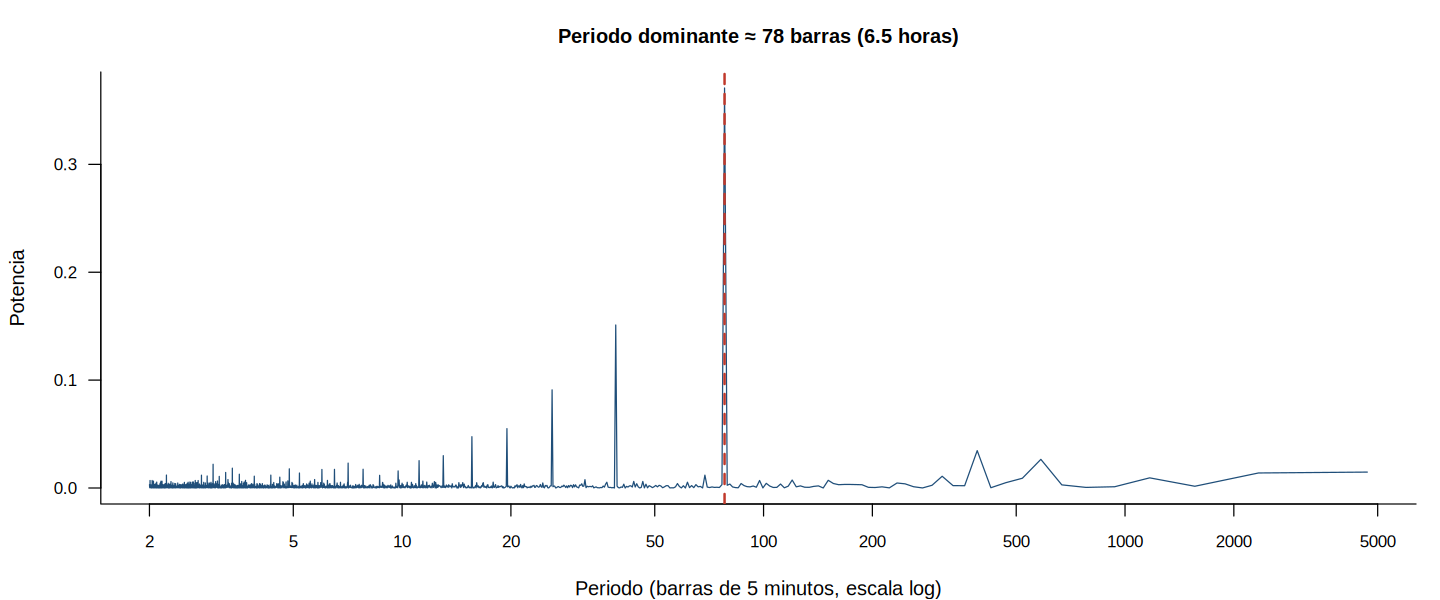

In [9]:
seccion("6. Series de tiempo: metodología Box-Jenkins")
seccion("6.1 Estacionariedad", 3)
series_d <- c(lapply(setNames(TICKERS, TICKERS), function(tk) precios[, tk]), list(PORTAFOLIO = port_val))
estac <- t(sapply(series_d, function(s) {
  lp <- log(as.numeric(s))
  c(`ADF nivel p` = tseries::adf.test(lp)$p.value, `ADF rend. p` = tseries::adf.test(diff(lp))$p.value,
    `KPSS nivel p` = tseries::kpss.test(lp)$p.value, `KPSS rend. p` = tseries::kpss.test(diff(lp))$p.value,
    `d sugerida` = forecast::ndiffs(lp))
}))
estac <- data.frame(estac, Conclusión = ifelse(estac[, "ADF nivel p"] > 0.05 & estac[, "ADF rend. p"] < 0.05, "I(1): raíz unitaria en niveles", "revisar"),
                    check.names = FALSE)
tabla(estac, "Pruebas de raíz unitaria (ADF: H0 raíz unitaria; KPSS: H0 estacionariedad)", 4, "Serie")
texto("Los log-precios no son estacionarios (ADF no rechaza la raíz unitaria y KPSS sí rechaza la estacionariedad), mientras que sus primeras diferencias, los rendimientos, sí lo son. Las series son integradas de orden uno, I(1): se modelan los rendimientos con ARMA(p,q) o, equivalentemente, el log-precio con ARIMA(p,1,q).")

seccion("6.2 Descomposición, periodicidad y persistencia", 3)
hurst <- function(lp, lags = 2:100) { tau <- sapply(lags, function(l) sd(lp[(l + 1):length(lp)] - lp[1:(length(lp) - l)])); unname(coef(lm(log(tau) ~ log(lags)))[2]) }
H_tab <- data.frame(Hurst = sapply(series_d, function(s) hurst(log(as.numeric(s)))))
H_tab$Interpretación <- ifelse(H_tab$Hurst > 0.55, "persistente (tendencia)", ifelse(H_tab$Hurst < 0.45, "reversión a la media", "≈ paseo aleatorio"))
tabla(H_tab, "Exponente de Hurst del log-precio (H = 0.5: paseo aleatorio)", 3, "Serie")

v60_full <- {M <- apply(I60$P[, TICKERS], 2, function(v) zoo::na.locf(rellenar(v), fromLast = TRUE, na.rm = FALSE)); as.numeric(M %*% acc)}
BARRAS_DIA <- as.integer(names(which.max(table(table(I60$dia)))))
y60 <- ts(log(tail(v60_full, 70 * BARRAS_DIA)), frequency = BARRAS_DIA)
stl60 <- stl(y60, s.window = "periodic", robust = TRUE)
comp_stl <- stl60$time.series
fuerza <- data.frame(Valor = c(max(0, 1 - var(comp_stl[, "remainder"]) / var(comp_stl[, "trend"] + comp_stl[, "remainder"])),
                               max(0, 1 - var(comp_stl[, "remainder"]) / var(comp_stl[, "seasonal"] + comp_stl[, "remainder"]))),
                     row.names = c("Fuerza de la tendencia", "Fuerza de la estacionalidad intradía"))
figura(sprintf("Descomposición STL del log-valor horario del portafolio (periodo = %d barras = 1 sesión)", BARRAS_DIA), function() {
  plot(stl60, main = "STL: datos, estacionalidad, tendencia y residuo (últimos 70 días, barras de 60 min)", col = COL[1])
}, 12, 7)
tabla(fuerza, "Fuerza de los componentes STL (0 = nula, 1 = total)", 3, "Componente")

x5 <- abs(p5$r) - mean(abs(p5$r)); n5 <- length(x5)
pot <- Mod(fft(x5))^2; k <- 2:floor(n5 / 2); periodo <- n5 / (k - 1)
PER_FFT <- periodo[which.max(pot[k])]
figura("Periodograma (FFT) de la volatilidad de 5 minutos del portafolio", function() {
  estilo()
  plot(periodo, pot[k], type = "l", log = "x", col = COL[1], xlab = "Periodo (barras de 5 minutos, escala log)", ylab = "Potencia",
       main = sprintf("Periodo dominante ≈ %.0f barras (%.1f horas)", PER_FFT, PER_FFT * 5 / 60))
  abline(v = PER_FFT, col = COL[2], lty = 2, lwd = 2)
})
texto(sprintf("La descomposición STL muestra una estacionalidad intradía débil frente a la tendencia (fuerza de estacionalidad = %.2f) en el nivel de precios. La transformada de Fourier aplicada a la volatilidad sí detecta un ciclo dominante de %.0f barras de 5 minutos (≈ %.1f horas, una sesión bursátil): la volatilidad sí tiene estacionalidad diaria, aunque el precio no. El exponente de Hurst promedio de las acciones es %.2f, cercano a 0.5 (paseo aleatorio); el del portafolio, %.2f, sugiere cierta reversión a la media, aunque este estimador es sensible a la muestra y debe tomarse con cautela.",
              fuerza[2, 1], PER_FFT, PER_FFT * 5 / 60, mean(H_tab[TICKERS, "Hurst"]), H_tab["PORTAFOLIO", "Hurst"]))


6.3 Identificación: ACF y PACF

Tabla 18. Prueba Ljung-Box sobre los rendimientos diarios del portafolio
 Rezagos p Ljung-Box rendimientos p Ljung-Box rendimientos²
       5                   0.4682                    0.0048
      10                   0.3477                    0.0000
      20                   0.0635                    0.0000

La ACF y la PACF de los rendimientos tienen pocos rezagos fuera de las bandas de confianza, lo que sugiere
modelos de orden bajo (AR(1), MA(1) o ARMA(1,1)). En cambio, los rendimientos al cuadrado muestran
autocorrelación fuerte y persistente: hay efectos ARCH, que justifican el modelo GARCH de la sección 7.


6.4 Estimación de modelos AR, MA, ARMA y ARIMA

Tabla 19. Modelos estimados sobre los rendimientos diarios del portafolio (*** p<0.01, ** p<0.05, * p<0.1)
    Modelo      AIC      BIC Log-verosimilitud p Ljung-Box (10)
     AR(1) -7599.31 -7583.91           3802.66             0.31
     AR(2) -7599.51 -7578.98           3803.76            

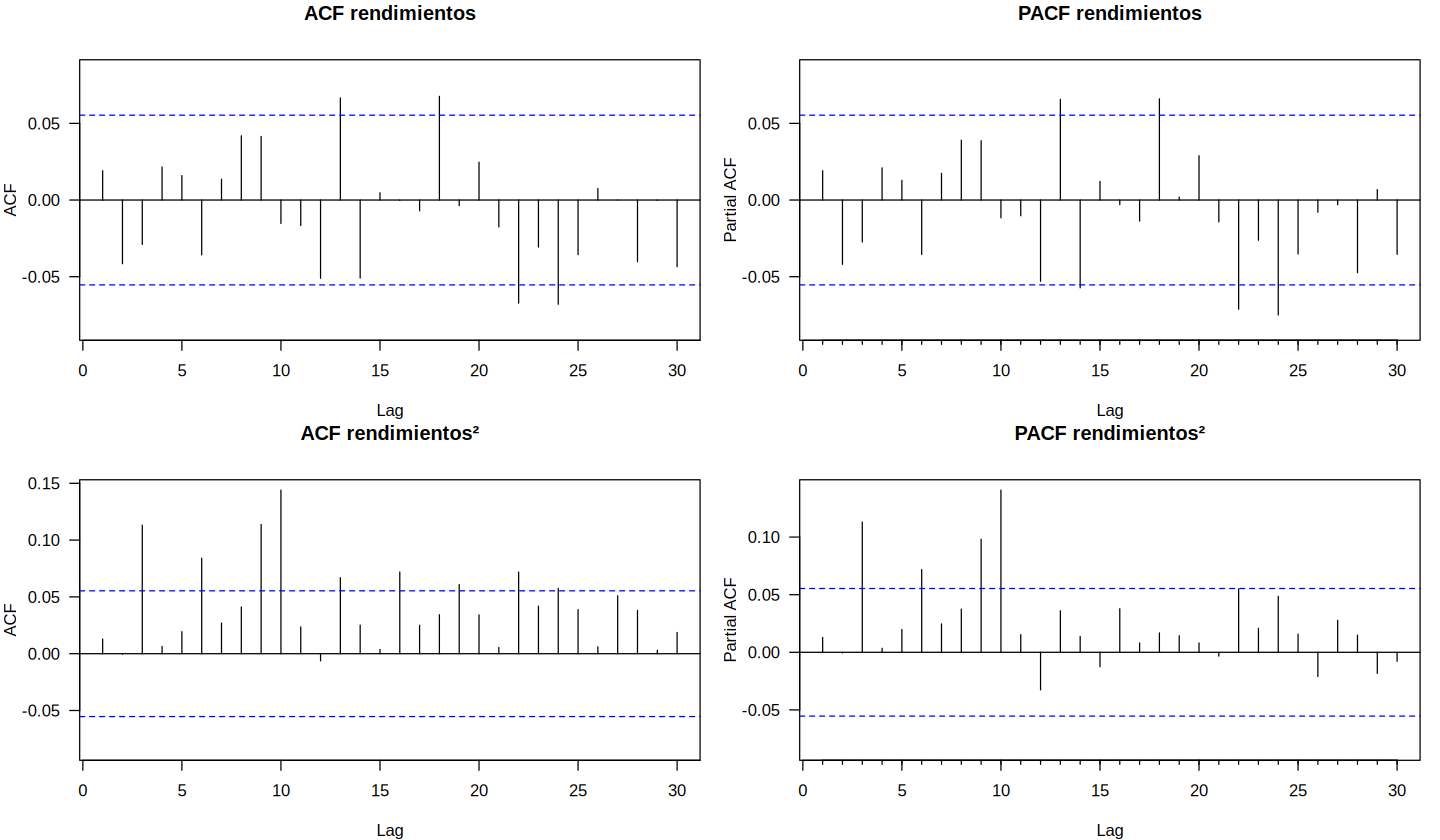


Tabla 20. Ljung-Box sobre los residuos del ARMA(2,2)
 Rezagos p Ljung-Box residuos p Ljung-Box residuos²
       5               0.5240                0.0107
      10               0.6836                0.0000
      20               0.1097                0.0000

Los p-valores de Ljung-Box sobre los residuos (0.524, 0.684, 0.110) indican que se comportan como ruido
blanco. Los residuos al cuadrado sí están autocorrelacionados y las colas son más pesadas que la normal: la
media queda bien modelada por el ARMA, pero la varianza no es constante, lo que se resuelve con GARCH.



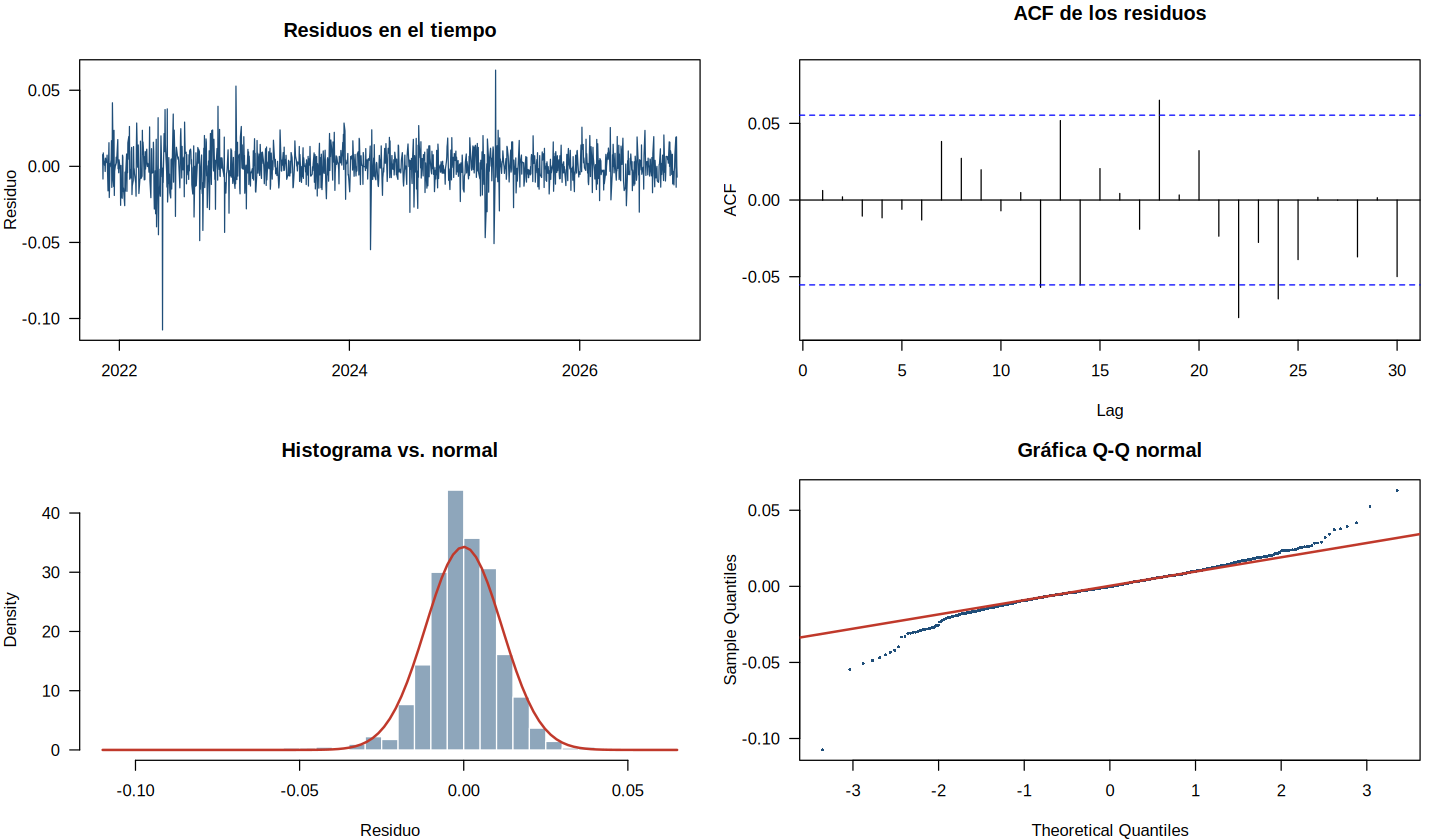

In [10]:
seccion("6.3 Identificación: ACF y PACF", 3)
figura("ACF y PACF de los rendimientos diarios del portafolio y de sus cuadrados", function() {
  par(mfrow = c(2, 2), mar = c(4, 4, 3, 1), las = 1)
  forecast::Acf(rp, lag.max = 30, main = "ACF rendimientos")
  forecast::Pacf(rp, lag.max = 30, main = "PACF rendimientos")
  forecast::Acf(rp^2, lag.max = 30, main = "ACF rendimientos²")
  forecast::Pacf(rp^2, lag.max = 30, main = "PACF rendimientos²")
}, 12, 7)
lb <- sapply(c(5, 10, 20), function(l) c(Box.test(rp, l, "Ljung-Box")$p.value, Box.test(rp^2, l, "Ljung-Box")$p.value))
tabla(data.frame(`Rezagos` = c(5, 10, 20), `p Ljung-Box rendimientos` = lb[1, ], `p Ljung-Box rendimientos²` = lb[2, ], check.names = FALSE),
      "Prueba Ljung-Box sobre los rendimientos diarios del portafolio", 4)
texto("La ACF y la PACF de los rendimientos tienen pocos rezagos fuera de las bandas de confianza, lo que sugiere modelos de orden bajo (AR(1), MA(1) o ARMA(1,1)). En cambio, los rendimientos al cuadrado muestran autocorrelación fuerte y persistente: hay efectos ARCH, que justifican el modelo GARCH de la sección 7.")

seccion("6.4 Estimación de modelos AR, MA, ARMA y ARIMA", 3)
candidatos <- list(`AR(1)` = c(1, 0, 0), `AR(2)` = c(2, 0, 0), `MA(1)` = c(0, 0, 1), `MA(2)` = c(0, 0, 2),
                   `ARMA(1,1)` = c(1, 0, 1), `ARMA(2,1)` = c(2, 0, 1), `ARMA(1,2)` = c(1, 0, 2), `ARMA(2,2)` = c(2, 0, 2))
ajustes <- lapply(candidatos, function(o) tryCatch(forecast::Arima(rp, order = o, include.mean = TRUE, method = "ML"), error = function(e) NULL))
ajustes <- Filter(Negate(is.null), ajustes)
coef_txt <- function(fit) {
  ct <- lmtest::coeftest(fit)
  est <- ifelse(ct[, 4] < 0.01, "***", ifelse(ct[, 4] < 0.05, "**", ifelse(ct[, 4] < 0.1, "*", "")))
  paste0(rownames(ct), " = ", formatC(ct[, 1], format = "f", digits = 4), est, collapse = "; ")
}
est_tab <- data.frame(
  AIC = sapply(ajustes, AIC), BIC = sapply(ajustes, BIC), `Log-verosimilitud` = sapply(ajustes, function(f) as.numeric(logLik(f))),
  `p Ljung-Box (10)` = sapply(names(ajustes), function(nm) Box.test(residuals(ajustes[[nm]]), 10, "Ljung-Box", fitdf = sum(candidatos[[nm]][c(1, 3)]))$p.value),
  Coeficientes = sapply(ajustes, coef_txt), check.names = FALSE)
tabla(est_tab, "Modelos estimados sobre los rendimientos diarios del portafolio (*** p<0.01, ** p<0.05, * p<0.1)", 2, "Modelo")
MEJOR_AIC <- rownames(est_tab)[which.min(est_tab$AIC)]; MEJOR_BIC <- rownames(est_tab)[which.min(est_tab$BIC)]
ORDEN_P <- candidatos[[MEJOR_AIC]]
auto_p <- forecast::auto.arima(log(port_val), d = 1, ic = "aic", max.p = 3, max.q = 3, stepwise = FALSE, approximation = FALSE)
print(summary(auto_p))
texto(sprintf("Por AIC el mejor modelo para los rendimientos es %s y por BIC %s. Como los rendimientos son la primera diferencia del log-precio, %s sobre los rendimientos equivale a ARIMA(%d,1,%d) sobre el log-valor del portafolio. La búsqueda automática (auto.arima) sobre el log-valor selecciona %s. Las diferencias de AIC entre modelos son menores a 3 puntos, señal de que la parte predecible de los rendimientos es reducida.%s",
              MEJOR_AIC, MEJOR_BIC, MEJOR_AIC, ORDEN_P[1], ORDEN_P[3], as.character(auto_p),
              if (MEJOR_AIC != MEJOR_BIC) sprintf(" El BIC, que penaliza más los parámetros, prefiere %s; en %s los coeficientes AR y MA de orden alto tienden a compensarse (raíces casi comunes), un síntoma de sobreparametrización. Por eso se reporta %s por su ajuste y se contrasta su pronóstico contra el paseo aleatorio.", MEJOR_BIC, MEJOR_AIC, MEJOR_AIC) else ""))

seccion("6.5 Diagnóstico de residuos", 3)
fit_best <- ajustes[[MEJOR_AIC]]; res_b <- residuals(fit_best)
figura(sprintf("Diagnóstico de residuos del modelo %s", MEJOR_AIC), function() {
  par(mfrow = c(2, 2), mar = c(4, 4, 3, 1), las = 1)
  plot(fechas[-1], res_b, type = "l", col = COL[1], xlab = "", ylab = "Residuo", main = "Residuos en el tiempo")
  forecast::Acf(res_b, lag.max = 30, main = "ACF de los residuos")
  hist(res_b, breaks = 60, freq = FALSE, col = adjustcolor(COL[1], 0.5), border = "white", main = "Histograma vs. normal", xlab = "Residuo")
  curve(dnorm(x, mean(res_b), sd(res_b)), add = TRUE, col = COL[2], lwd = 2)
  qqnorm(res_b, pch = 16, cex = 0.4, col = COL[1], main = "Gráfica Q-Q normal"); qqline(res_b, col = COL[2], lwd = 2)
}, 12, 7)
lb_r <- sapply(c(5, 10, 20), function(l) Box.test(res_b, l, "Ljung-Box", fitdf = sum(ORDEN_P[c(1, 3)]))$p.value)
tabla(data.frame(Rezagos = c(5, 10, 20), `p Ljung-Box residuos` = lb_r, `p Ljung-Box residuos²` = sapply(c(5, 10, 20), function(l) Box.test(res_b^2, l, "Ljung-Box")$p.value), check.names = FALSE),
      sprintf("Ljung-Box sobre los residuos del %s", MEJOR_AIC), 4)
texto(sprintf("Los p-valores de Ljung-Box sobre los residuos (%s) indican %s. Los residuos al cuadrado sí están autocorrelacionados y las colas son más pesadas que la normal: la media queda bien modelada por el ARMA, pero la varianza no es constante, lo que se resuelve con GARCH.",
              paste(f2(lb_r, 3), collapse = ", "), ifelse(min(lb_r) > 0.05, "que se comportan como ruido blanco", "cierta autocorrelación remanente en algunos rezagos")))


6.6 Pronóstico diario (forecast)

Tabla 21. ARIMA diario: validación con los últimos 20 días y pronóstico a 10 días hábiles (IC 95%)
      Serie                  Modelo      AIC RMSE ARIMA RMSE paseo aleatorio
 PORTAFOLIO ARIMA(2,1,2) with drift -7600.32   16384.81             19243.72
       COST ARIMA(1,1,1) with drift -7044.66      64.71                64.80
        KOF ARIMA(0,1,0) with drift -6884.66       6.02                 6.77
       GOOG            ARIMA(0,1,0) -6196.04      42.46                42.46
       NVDA ARIMA(1,1,0) with drift -5038.91      25.64                21.19
        TGT            ARIMA(0,1,0) -5861.05       3.71                 3.71
        BAC            ARIMA(0,1,1) -6693.81       3.63                 3.58
       MSFT            ARIMA(0,1,0) -6541.76      10.37                10.37
       AMZN            ARIMA(0,1,0) -5893.62      10.65                10.65
       AAPL            ARIMA(0,1,0) -6559.72       7.82                 7.82
 MAPE %    Último P

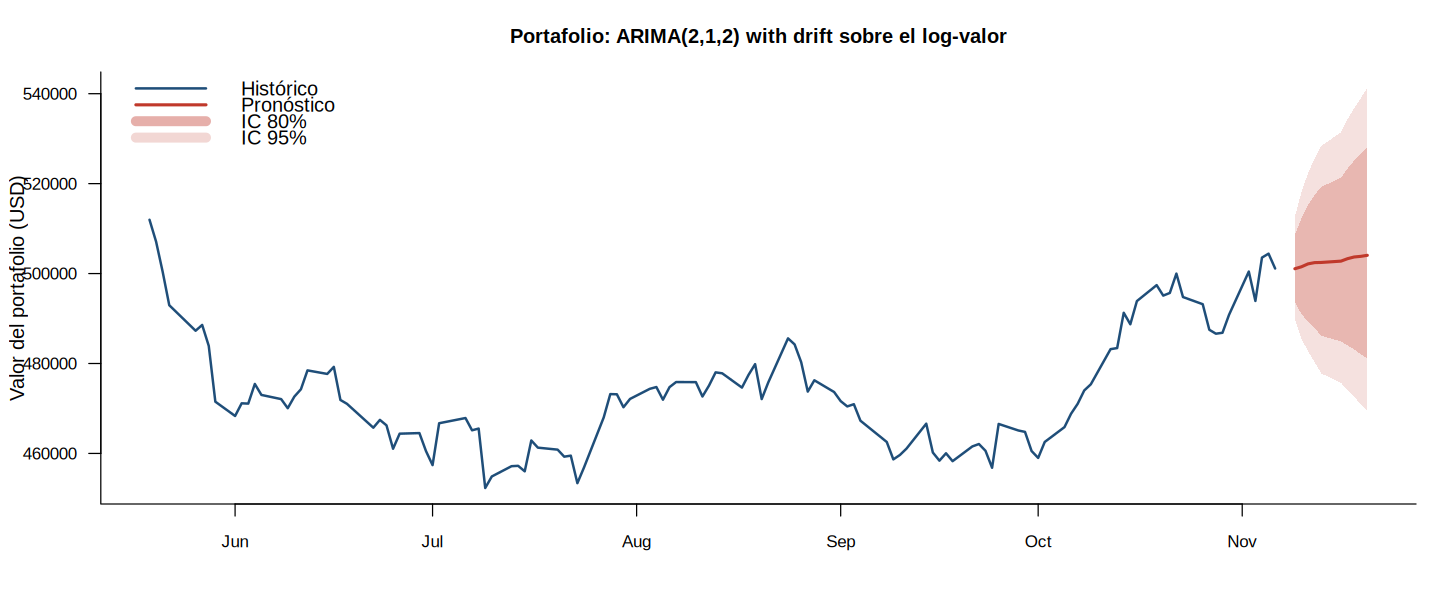

El modelo ARIMA tuvo menor error de pronóstico que el paseo aleatorio en 3 de 10 series durante los últimos
20 días. El pronóstico del portafolio a 10 días es $504,061.02, con intervalo de 95% entre $469,408.61 y
$541,271.51. Los intervalos se amplían con el horizonte y los pronósticos puntuales son casi planos:
consistente con la hipótesis de mercados eficientes en su forma débil, donde los precios pasados aportan poca
información sobre los futuros.



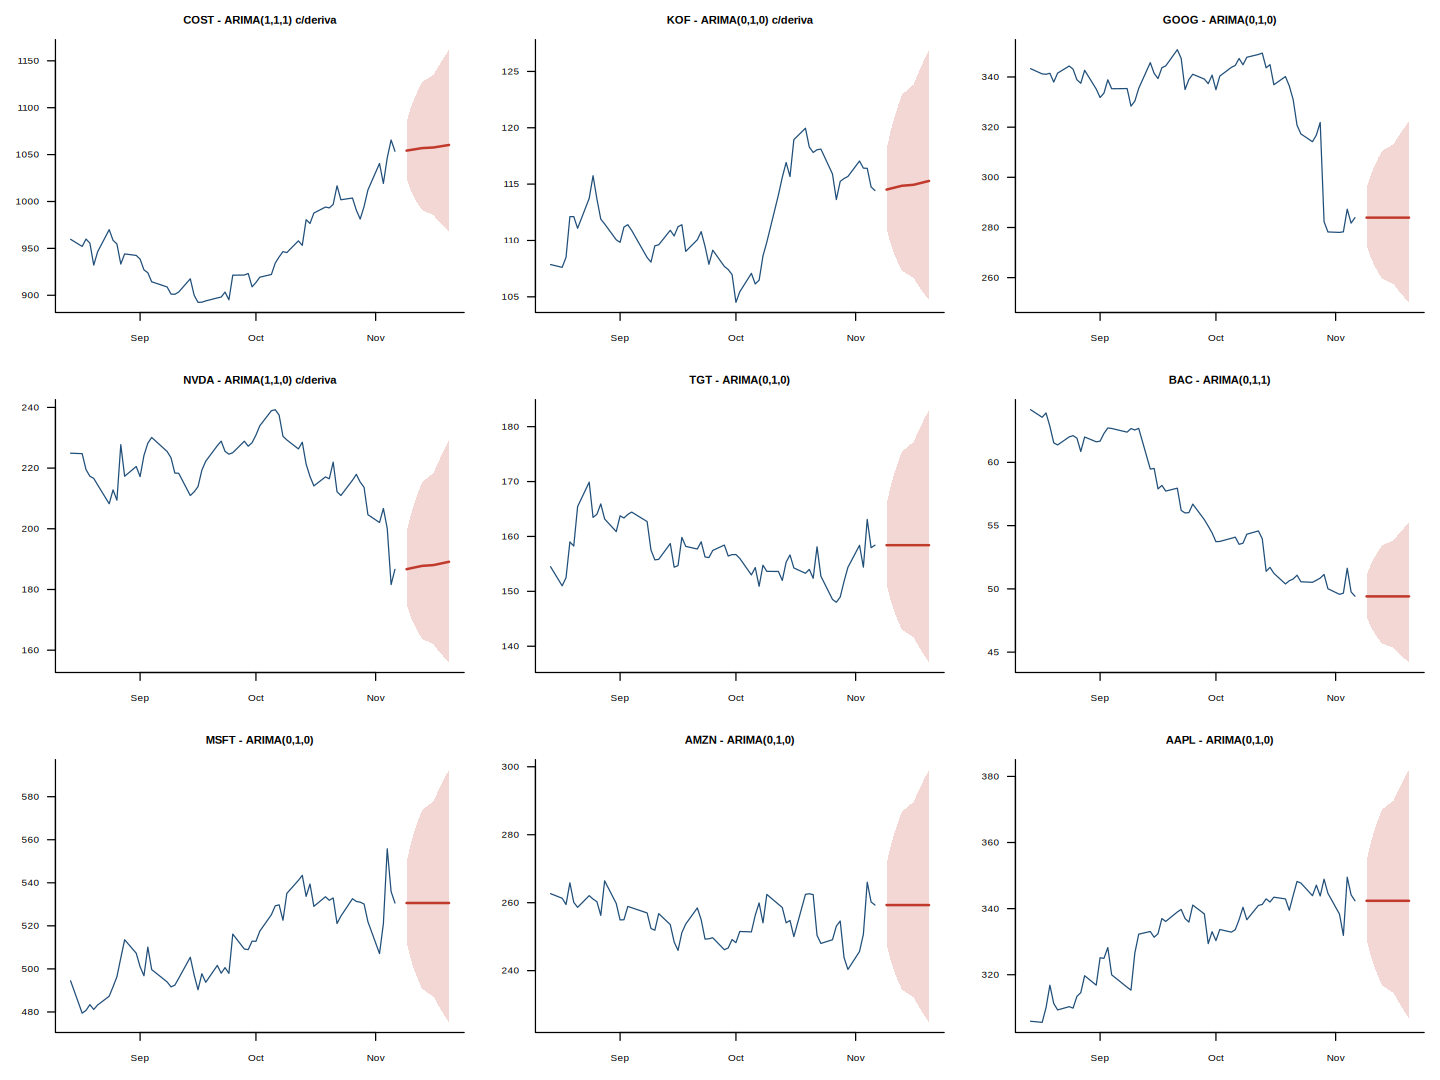

In [11]:
seccion("6.6 Pronóstico diario (forecast)", 3)
dias_futuros <- function(ultimo, h) { f <- seq(ultimo + 1, by = "day", length.out = h * 2 + 7); f <- f[as.POSIXlt(f)$wday %in% 1:5]; f[1:h] }
pronosticar <- function(precio, h, prueba, orden = NULL) {
  y <- log(as.numeric(precio)); n <- length(y)
  ajusta <- function(z) if (is.null(orden)) forecast::auto.arima(z, d = 1, ic = "aic", stepwise = TRUE, approximation = FALSE)
                        else forecast::Arima(z, order = orden, include.drift = TRUE)
  fb <- ajusta(y[1:(n - prueba)]); pred <- exp(as.numeric(forecast::forecast(fb, h = prueba)$mean)); real <- exp(y[(n - prueba + 1):n])
  fit <- ajusta(y); fc <- forecast::forecast(fit, h = h, level = c(80, 95))
  list(fit = fit, fc = fc,
       info = c(AIC = AIC(fit), `RMSE ARIMA` = sqrt(mean((pred - real)^2)), `RMSE paseo aleatorio` = sqrt(mean((exp(y[n - prueba]) - real)^2)),
                `MAPE %` = mean(abs(pred / real - 1)) * 100, Último = exp(y[n]), Pronóstico = exp(tail(as.numeric(fc$mean), 1)),
                `LI 95%` = exp(tail(fc$lower[, 2], 1)), `LS 95%` = exp(tail(fc$upper[, 2], 1))),
       modelo = as.character(fit))
}
PR <- c(list(PORTAFOLIO = pronosticar(port_val, H_DIAS, 20, c(ORDEN_P[1], 1, ORDEN_P[3]))),
        lapply(setNames(TICKERS, TICKERS), function(tk) pronosticar(precios[, tk], H_DIAS, 20)))
arima_d <- data.frame(Modelo = sapply(PR, `[[`, "modelo"), t(sapply(PR, `[[`, "info")), check.names = FALSE)
arima_d$`Cambio esperado %` <- (arima_d$Pronóstico / arima_d$Último - 1) * 100
tabla(arima_d, sprintf("ARIMA diario: validación con los últimos 20 días y pronóstico a %d días hábiles (IC 95%%)", H_DIAS), 2, "Serie")
GANA_ARIMA <- sum(arima_d$`RMSE ARIMA` < arima_d$`RMSE paseo aleatorio`)

ff <- dias_futuros(tail(fechas, 1), H_DIAS); fcp <- PR$PORTAFOLIO$fc
figura(sprintf("Pronóstico del valor del portafolio a %d días hábiles con intervalos de 80%% y 95%%", H_DIAS), function() {
  estilo()
  k <- 120; hx <- tail(fechas, k); hy <- tail(port_val, k)
  plot(c(hx, ff), c(hy, rep(NA, H_DIAS)), type = "l", lwd = 2, col = COL[1], ylim = range(hy, exp(fcp$lower[, 2]), exp(fcp$upper[, 2])),
       xlab = "", ylab = "Valor del portafolio (USD)", main = paste("Portafolio:", PR$PORTAFOLIO$modelo, "sobre el log-valor"))
  polygon(c(ff, rev(ff)), c(exp(fcp$lower[, 2]), rev(exp(fcp$upper[, 2]))), col = adjustcolor(COL[2], 0.15), border = NA)
  polygon(c(ff, rev(ff)), c(exp(fcp$lower[, 1]), rev(exp(fcp$upper[, 1]))), col = adjustcolor(COL[2], 0.25), border = NA)
  lines(ff, exp(fcp$mean), col = COL[2], lwd = 2.5)
  legend("topleft", c("Histórico", "Pronóstico", "IC 80%", "IC 95%"), col = c(COL[1], COL[2], adjustcolor(COL[2], 0.4), adjustcolor(COL[2], 0.2)),
         lwd = c(2, 2.5, 8, 8), bty = "n")
})
figura(sprintf("Pronóstico ARIMA a %d días por acción (IC 95%%)", H_DIAS), function() {
  par(mfrow = c(3, 3), mar = c(3, 3.5, 2.5, 1), las = 1, cex.axis = 0.75)
  for (tk in TICKERS) {
    fc <- PR[[tk]]$fc; hy <- tail(precios[, tk], 60); hx <- tail(fechas, 60)
    plot(c(hx, ff), c(hy, rep(NA, H_DIAS)), type = "l", col = COL[1], ylim = range(hy, exp(fc$lower[, 2]), exp(fc$upper[, 2])),
         xlab = "", ylab = "", main = paste(tk, "-", sub(" with drift", " c/deriva", PR[[tk]]$modelo)), cex.main = 0.85)
    polygon(c(ff, rev(ff)), c(exp(fc$lower[, 2]), rev(exp(fc$upper[, 2]))), col = adjustcolor(COL[2], 0.2), border = NA)
    lines(ff, exp(fc$mean), col = COL[2], lwd = 2)
  }
}, 12, 9)
texto(sprintf("El modelo ARIMA tuvo menor error de pronóstico que el paseo aleatorio en %d de %d series durante los últimos 20 días. El pronóstico del portafolio a %d días es $%s, con intervalo de 95%% entre $%s y $%s. Los intervalos se amplían con el horizonte y los pronósticos puntuales son casi planos: consistente con la hipótesis de mercados eficientes en su forma débil, donde los precios pasados aportan poca información sobre los futuros.",
              GANA_ARIMA, nrow(arima_d), H_DIAS, f2(arima_d["PORTAFOLIO", "Pronóstico"]), f2(arima_d["PORTAFOLIO", "LI 95%"]), f2(arima_d["PORTAFOLIO", "LS 95%"])))


6.7 Pronóstico intradía: horas y minutos

Tabla 22. Pronóstico del portafolio por hora: validación con la última sesión (7 barras de 60 min)
                          Modelo         Especificación RMSE (USD) MAPE %
                          SARIMA ARIMA(0,1,0)(0,0,2)[7]   1483.646  0.227
                           ARIMA           ARIMA(0,1,0)   2454.247  0.438
                 Paseo aleatorio           ARIMA(0,1,0)   2454.247  0.438
 ETS (suavizamiento exponencial)            ETS(M,Ad,A)   2634.401  0.500


Tabla 23. Pronóstico intradía del valor del portafolio
             Serie                 Modelo  Horizonte   Último Pronóstico
 Portafolio 60 min ARIMA(0,1,0)(0,0,2)[7]    7 horas 501001.4   500802.9
  Portafolio 5 min           ARIMA(2,1,2) 60 minutos 501001.4   500948.7
  Portafolio 1 min           ARIMA(3,1,0) 30 minutos 501001.4   501001.3
   LI 95%   LS 95%
 491293.1 510496.7
 496758.4 505174.3
 497200.8 504830.8


Tabla 24. Pronóstico ARIMA por acción a 7 horas
 Acción  Últi

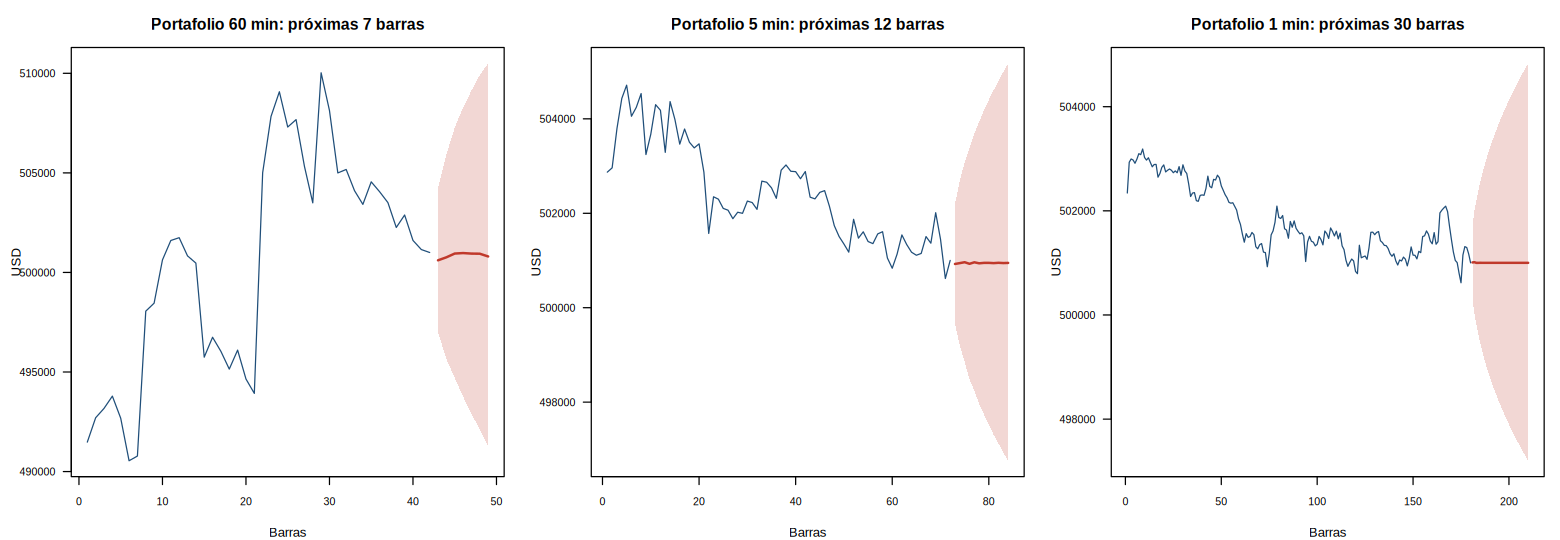

In [12]:
seccion("6.7 Pronóstico intradía: horas y minutos", 3)
valor_intra <- function(I) { M <- apply(I$P[, TICKERS], 2, function(v) zoo::na.locf(rellenar(v), fromLast = TRUE, na.rm = FALSE)); as.numeric(M %*% acc) }
v60 <- tail(valor_intra(I60), 100 * BARRAS_DIA); v5 <- tail(valor_intra(I5), 20 * 78); v1 <- valor_intra(I1)

# Comparación de modelos por hora: ARIMA, SARIMA, ETS (suavizamiento exponencial) y paseo aleatorio
y60s <- ts(log(v60), frequency = BARRAS_DIA); nh <- length(y60s); prueba_h <- BARRAS_DIA
ent <- ts(y60s[1:(nh - prueba_h)], frequency = BARRAS_DIA); real_h <- exp(y60s[(nh - prueba_h + 1):nh])
modelos_h <- list(
  ARIMA   = function(z) forecast::auto.arima(z, seasonal = FALSE, ic = "aic"),
  SARIMA  = function(z) forecast::auto.arima(z, seasonal = TRUE, ic = "aic", D = 0),
  `ETS (suavizamiento exponencial)` = function(z) forecast::ets(z),
  `Paseo aleatorio` = function(z) forecast::Arima(z, order = c(0, 1, 0)))
comp_h <- t(sapply(modelos_h, function(f) {
  fit <- tryCatch(f(ent), error = function(e) NULL)
  if (is.null(fit)) return(c(NA, NA))
  p <- exp(as.numeric(forecast::forecast(fit, h = prueba_h)$mean))
  c(sqrt(mean((p - real_h)^2)), mean(abs(p / real_h - 1)) * 100)
}))
colnames(comp_h) <- c("RMSE (USD)", "MAPE %")
nombres_mod <- sapply(modelos_h, function(f) tryCatch(as.character(f(y60s)), error = function(e) "no estimado"))
comp_h <- data.frame(Especificación = nombres_mod, comp_h, check.names = FALSE)
comp_h <- comp_h[order(comp_h$`RMSE (USD)`), ]
tabla(comp_h, sprintf("Pronóstico del portafolio por hora: validación con la última sesión (%d barras de 60 min)", prueba_h), 3, "Modelo")
MEJOR_H <- rownames(comp_h)[1]

fit_h <- modelos_h[[MEJOR_H]](y60s); fc_h <- forecast::forecast(fit_h, h = H_HORAS, level = 95)
fit_5 <- forecast::auto.arima(log(v5), ic = "aic"); fc_5 <- forecast::forecast(fit_5, h = H_5M, level = 95)
fit_1 <- forecast::auto.arima(log(v1), ic = "aic"); fc_1 <- forecast::forecast(fit_1, h = H_1M, level = 95)
intr <- data.frame(Modelo = c(as.character(fit_h), as.character(fit_5), as.character(fit_1)),
                   Horizonte = c(paste(H_HORAS, "horas"), paste(H_5M * 5, "minutos"), paste(H_1M, "minutos")),
                   Último = c(tail(v60, 1), tail(v5, 1), tail(v1, 1)),
                   Pronóstico = exp(c(tail(fc_h$mean, 1), tail(fc_5$mean, 1), tail(fc_1$mean, 1))),
                   `LI 95%` = exp(c(tail(fc_h$lower, 1), tail(fc_5$lower, 1), tail(fc_1$lower, 1))),
                   `LS 95%` = exp(c(tail(fc_h$upper, 1), tail(fc_5$upper, 1), tail(fc_1$upper, 1))),
                   check.names = FALSE, row.names = c("Portafolio 60 min", "Portafolio 5 min", "Portafolio 1 min"))
tabla(intr, "Pronóstico intradía del valor del portafolio", 2, "Serie")

acc_h <- t(sapply(TICKERS, function(tk) {
  p <- tail(apply(I60$P[, tk, drop = FALSE], 2, function(v) zoo::na.locf(rellenar(v), fromLast = TRUE, na.rm = FALSE))[, 1], 100 * BARRAS_DIA)
  fit <- forecast::auto.arima(log(p), ic = "aic"); fc <- forecast::forecast(fit, h = H_HORAS, level = 95)
  c(Último = unname(tail(p, 1)), Pronóstico = exp(tail(as.numeric(fc$mean), 1)), `LI 95%` = exp(tail(fc$lower[, 1], 1)), `LS 95%` = exp(tail(fc$upper[, 1], 1)))
}))
tabla(acc_h, sprintf("Pronóstico ARIMA por acción a %d horas", H_HORAS), 2, "Acción")

figura("Pronóstico del valor del portafolio por hora y por minuto (IC 95%)", function() {
  par(mfrow = c(1, 3), mar = c(4, 4.5, 3, 1), las = 1, cex.axis = 0.8)
  for (z in list(list(v = v60, fc = fc_h, h = H_HORAS, t = "60 min"), list(v = v5, fc = fc_5, h = H_5M, t = "5 min"), list(v = v1, fc = fc_1, h = H_1M, t = "1 min"))) {
    k <- min(length(z$v), 6 * z$h); x0 <- 1:k; x1 <- (k + 1):(k + z$h)
    plot(c(x0, x1), c(tail(z$v, k), rep(NA, z$h)), type = "l", col = COL[1], ylim = range(tail(z$v, k), exp(z$fc$lower), exp(z$fc$upper)),
         xlab = "Barras", ylab = "USD", main = paste0("Portafolio ", z$t, ": próximas ", z$h, " barras"))
    polygon(c(x1, rev(x1)), c(exp(z$fc$lower), rev(exp(z$fc$upper))), col = adjustcolor(COL[2], 0.2), border = NA)
    lines(x1, exp(z$fc$mean), col = COL[2], lwd = 2)
  }
}, 13, 4.5)
texto(sprintf("En datos por hora el mejor modelo fuera de muestra fue %s. A frecuencias de minutos los modelos seleccionados son de orden muy bajo y los intervalos de confianza son estrechos en valor absoluto pero crecen rápido con el horizonte: la información de corto plazo se incorpora casi de inmediato a los precios.", MEJOR_H))

## 7. GARCH (volatilidad condicional)
GARCH(1,1) con innovaciones t-Student: $\sigma_t^2 = \omega + \alpha u_{t-1}^2 + \beta \sigma_{t-1}^2$. Comparación con GJR-GARCH y EGARCH (efecto apalancamiento), pronóstico de volatilidad y valor en riesgo (VaR) al 95%.


7. Modelos GARCH

Tabla 25. GARCH(1,1) con distribución t: parámetros, volatilidad y VaR
              Activo      ω      α      β    α+β  ν (t) Vol. actual anual %
                COST 0.0497 0.0265 0.9485 0.9750 4.6102             22.7295
                 KOF 0.9615 0.0905 0.5124 0.6029 9.1748             23.5805
                GOOG 0.0631 0.0225 0.9639 0.9864 4.3091             41.0633
                NVDA 0.1615 0.0486 0.9359 0.9845 6.3603             52.4620
                 TGT 0.0327 0.0034 0.9886 0.9920 4.1328             32.1049
                 BAC 0.6308 0.1133 0.6727 0.7861 4.5367             34.8089
                MSFT 0.0706 0.0593 0.9220 0.9813 4.6589             37.5670
                AMZN 0.0365 0.0181 0.9746 0.9927 4.8214             36.7591
                AAPL 0.0785 0.0662 0.9122 0.9784 4.5329             30.1923
          PORTAFOLIO 0.0306 0.0336 0.9412 0.9749 5.7536             16.3901
 PORTAFOLIO (60 min) 0.0042 0.0401 0.9240 0.9640 3.6139             15.334

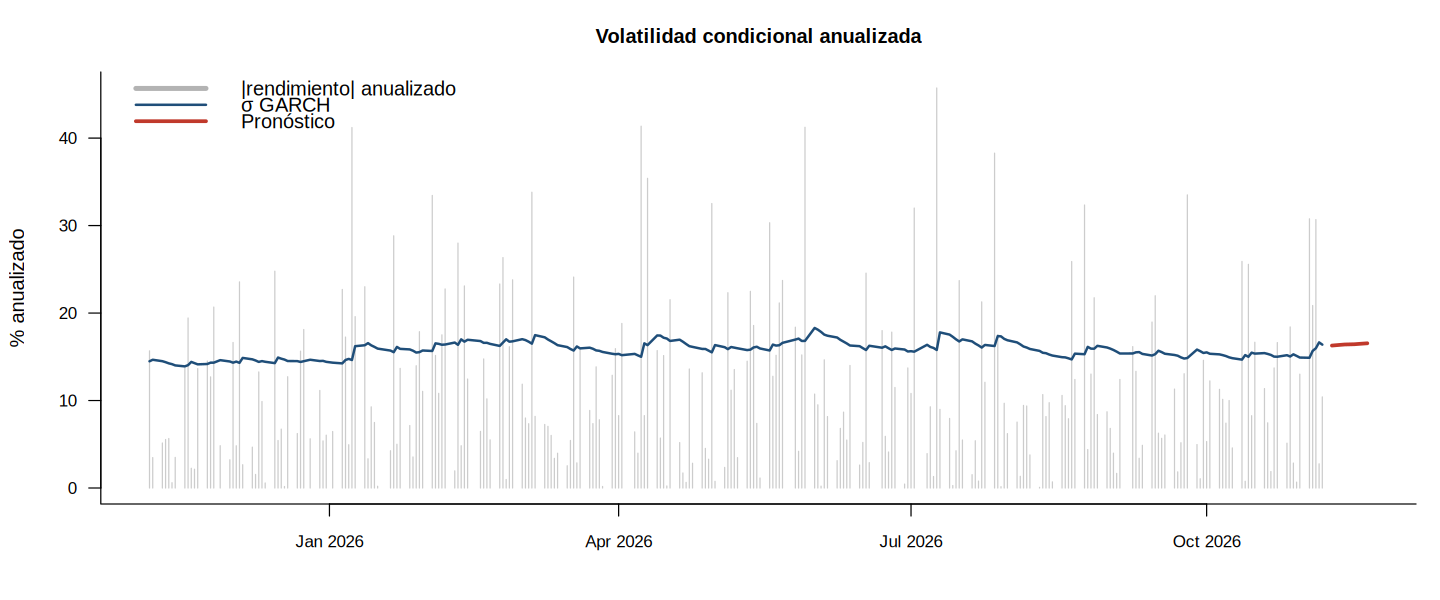

In [13]:
seccion("7. Modelos GARCH")
espec <- function(modelo) ugarchspec(variance.model = list(model = modelo, garchOrder = c(1, 1)),
                                              mean.model = list(armaOrder = c(0, 0), include.mean = TRUE), distribution.model = "std")
ajusta_garch <- function(r, modelo = "sGARCH") tryCatch(ugarchfit(espec(modelo), data = as.numeric(r) * 100, solver = "hybrid"), error = function(e) NULL)
resumen_garch <- function(fit, escala = 252, h = H_DIAS) {
  if (is.null(fit)) return(rep(NA, 8))
  cf <- coef(fit); s <- as.numeric(sigma(ugarchforecast(fit, n.ahead = h)))
  q05 <- qdist("std", 0.05, mu = 0, sigma = 1, shape = cf[["shape"]])
  c(omega = cf[["omega"]], alpha = cf[["alpha1"]], beta = cf[["beta1"]], persist = cf[["alpha1"]] + cf[["beta1"]], nu = cf[["shape"]],
    vol_act = tail(as.numeric(sigma(fit)), 1) * sqrt(escala),
    vol_pron = sqrt(mean(s^2) * escala), var95 = -(cf[["mu"]] + q05 * s[1]))
}
G <- c(lapply(setNames(TICKERS, TICKERS), function(tk) ajusta_garch(R[, tk])), list(PORTAFOLIO = ajusta_garch(rp)))
garch_tab <- t(sapply(G, resumen_garch))
rp60 <- p60$r
g60 <- ajusta_garch(rp60)
garch_tab <- rbind(garch_tab, `PORTAFOLIO (60 min)` = resumen_garch(g60, escala = 252 * BARRAS_DIA, h = H_HORAS))
colnames(garch_tab) <- c("ω", "α", "β", "α+β", "ν (t)", "Vol. actual anual %", "Vol. pronosticada anual %", "VaR 95% 1 periodo %")
tabla(garch_tab, "GARCH(1,1) con distribución t: parámetros, volatilidad y VaR", 4, "Activo")
print(G$PORTAFOLIO)
VAR_USD <- garch_tab["PORTAFOLIO", "VaR 95% 1 periodo %"] / 100 * VALOR_TOTAL
texto(sprintf("En el portafolio, α + β = %.3f: los choques de volatilidad son muy persistentes y se disipan lentamente. La volatilidad anualizada actual es %.1f%% y la pronosticada para los próximos %d días es %.1f%%. El VaR al 95%% a un día es %.2f%% del valor, es decir, $%s: en 1 de cada 20 días se esperaría una pérdida mayor a esa cifra.",
              garch_tab["PORTAFOLIO", "α+β"], garch_tab["PORTAFOLIO", "Vol. actual anual %"], H_DIAS, garch_tab["PORTAFOLIO", "Vol. pronosticada anual %"],
              garch_tab["PORTAFOLIO", "VaR 95% 1 periodo %"], f2(VAR_USD)))

modelos_g <- c(`GARCH(1,1)` = "sGARCH", `GJR-GARCH(1,1)` = "gjrGARCH", `EGARCH(1,1)` = "eGARCH")
comp_g <- t(sapply(modelos_g, function(m) {
  fit <- ajusta_garch(rp, m)
  if (is.null(fit)) return(rep(NA, 5))
  ic <- infocriteria(fit); cf <- coef(fit); mc <- fit@fit$robust.matcoef
  c(likelihood(fit), ic[1], ic[2], if ("gamma1" %in% names(cf)) cf[["gamma1"]] else NA,
    if ("gamma1" %in% rownames(mc)) mc["gamma1", 4] else NA)
}))
colnames(comp_g) <- c("Log-verosimilitud", "AIC", "BIC", "γ (asimetría)", "p γ (robusto)")
tabla(comp_g, "Comparación de modelos de volatilidad del portafolio (menor AIC = mejor)", 4, "Modelo")
MEJOR_GARCH <- rownames(comp_g)[which.min(comp_g[, "AIC"])]
P_GJR <- comp_g["GJR-GARCH(1,1)", "p γ (robusto)"]
texto(sprintf("El mejor modelo de volatilidad por AIC es %s, aunque las diferencias de AIC entre los tres son mínimas. En GJR-GARCH el término γ mide el efecto apalancamiento (las caídas aumentan la volatilidad más que las subidas de igual magnitud): γ = %.4f con p = %.3f, %s.",
              MEJOR_GARCH, comp_g["GJR-GARCH(1,1)", "γ (asimetría)"], P_GJR,
              ifelse(is.finite(P_GJR) & P_GJR < 0.05, "por lo que el efecto apalancamiento es significativo en el portafolio", "no significativo: en este portafolio, dominado por acciones defensivas de consumo, no hay evidencia clara de asimetría")))

sg <- as.numeric(sigma(G$PORTAFOLIO)) * sqrt(252)
sf <- as.numeric(sigma(ugarchforecast(G$PORTAFOLIO, n.ahead = H_DIAS))) * sqrt(252)
figura("Volatilidad condicional GARCH(1,1) del portafolio y pronóstico", function() {
  estilo()
  k <- 252; hx <- tail(fechas[-1], k)
  plot(c(hx, ff), c(tail(abs(rp), k) * 100 * sqrt(252), rep(NA, H_DIAS)), type = "h", col = "gray80",
       ylim = c(0, max(tail(abs(rp), k) * 100 * sqrt(252), sg, sf)), xlab = "", ylab = "% anualizado", main = "Volatilidad condicional anualizada")
  lines(hx, tail(sg, k), col = COL[1], lwd = 2); lines(ff, sf, col = COL[2], lwd = 3)
  legend("topleft", c("|rendimiento| anualizado", "σ GARCH", "Pronóstico"), col = c("gray70", COL[1], COL[2]), lwd = c(4, 2, 3), bty = "n")
})

## 8. Estrategias del portafolio
Pesos estimados con datos hasta hace seis meses y evaluados en los últimos seis meses (fuera de muestra). Restricciones: sin ventas en corto y máximo 30% por acción. Estrategias: portafolio actual de HowTheMarketWorks, igual peso, mínima varianza, máximo Sharpe y momentum.


8. Estrategias del portafolio

Tabla 27. Pesos por estrategia (%), estimados con datos de entrenamiento
 Acción Actual (HTMW) Igual peso Mínima varianza Máximo Sharpe Momentum top 4
   COST          63.1       11.1            30.0            30              0
    KOF          22.8       11.1            30.0            30             25
   GOOG           5.7       11.1             3.0            14             25
   NVDA           3.7       11.1             0.0            26             25
    TGT           1.6       11.1             1.9             0             25
    BAC           1.5       11.1            18.9             0              0
   MSFT           1.1       11.1            14.5             0              0
   AMZN           0.5       11.1             0.0             0              0
   AAPL           0.1       11.1             1.7             0              0


Tabla 28. Desempeño fuera de muestra (últimos 126 días hábiles)
      Estrategia Rend. acumulado % Rend. anual % 

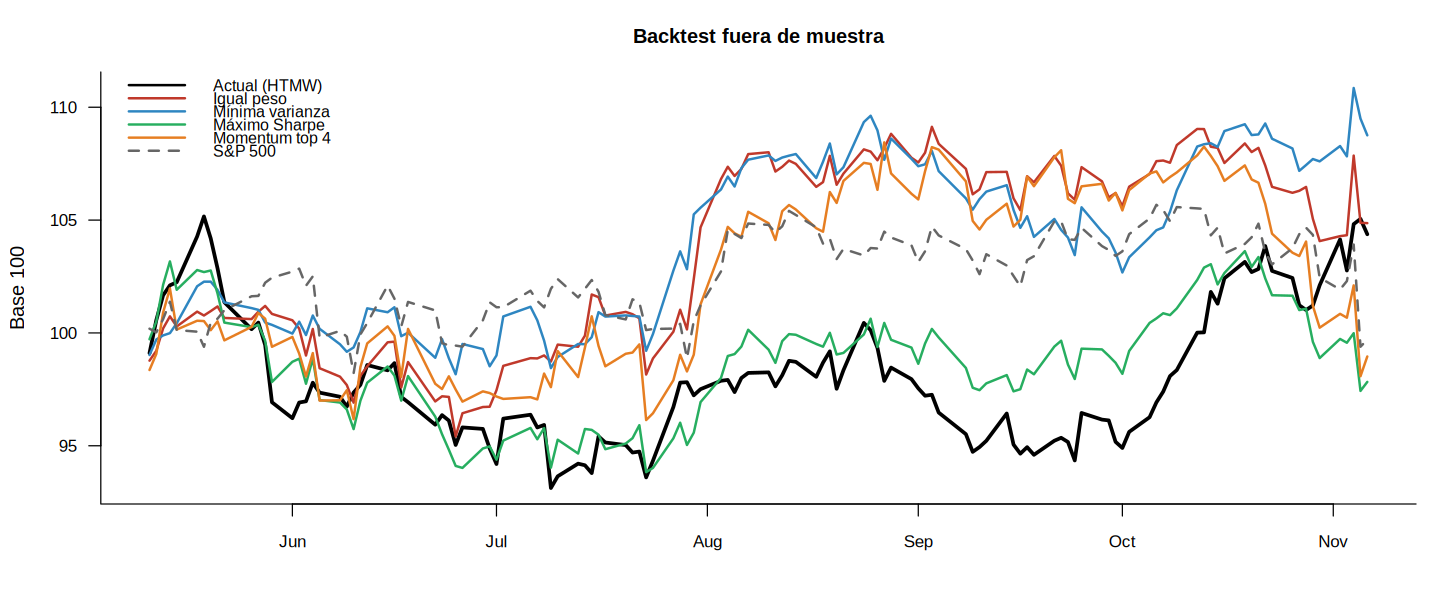


Tabla 29. Rebalanceo hacia la estrategia «Mínima varianza» (pesos re-estimados con toda la muestra)
 Acción Acciones actuales Peso objetivo % Acciones objetivo Diferencia
   COST               300            30.0               142       -158
    KOF              1000            30.0              1313        313
   GOOG               100             3.8                67        -33
   NVDA               100             0.0                 0       -100
    TGT                50             1.7                53          3
    BAC               150            19.6              1990       1840
   MSFT                10            12.2               115        105
   AMZN                10             0.0                 0        -10
   AAPL                 1             2.6                38         37
 Orden en HTMW
    Vender 158
   Comprar 313
     Vender 33
    Vender 100
     Comprar 3
  Comprar 1840
   Comprar 105
     Vender 10
    Comprar 37

Fuera de muestra, la mejor razón de Sh

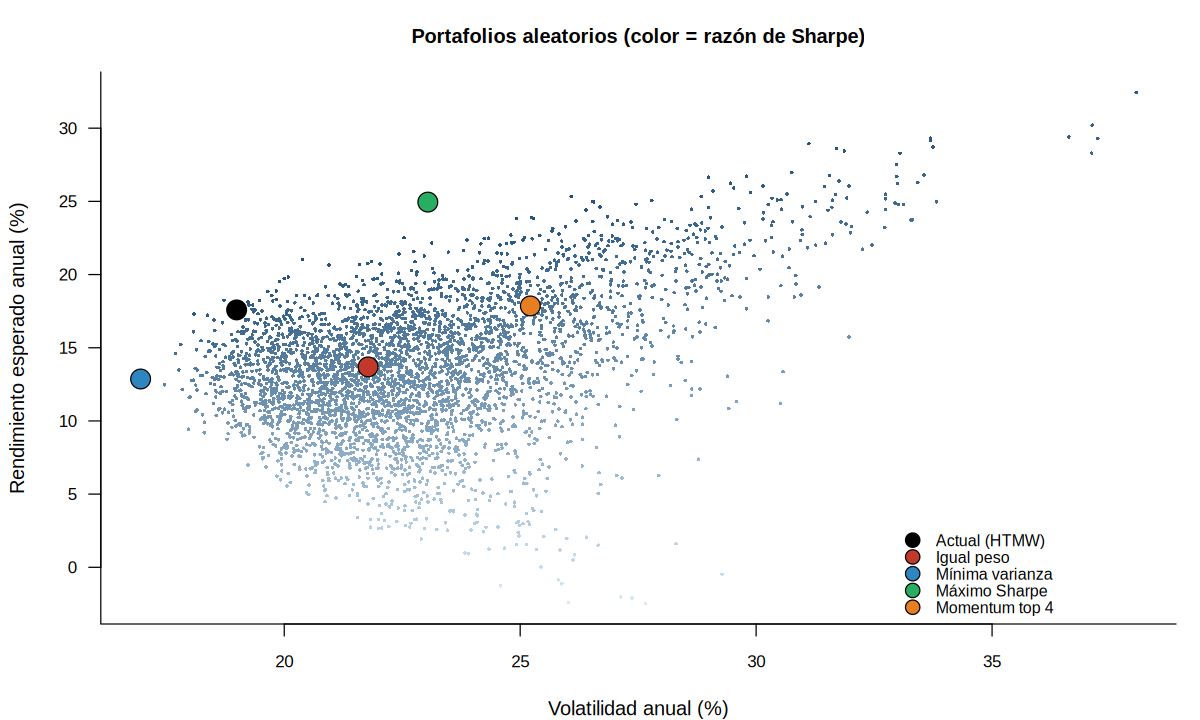

In [14]:
seccion("8. Estrategias del portafolio")
N_PRUEBA <- 126; WMAX <- 0.30; n_act <- length(TICKERS)
Rs <- exp(R) - 1; rb_s <- exp(rmk) - 1
n_tot <- nrow(R); ent_idx <- 1:(n_tot - N_PRUEBA); pru_idx <- (n_tot - N_PRUEBA + 1):n_tot

min_var <- function(S) {
  sol <- quadprog::solve.QP(Dmat = 2 * S + diag(1e-8, n_act), dvec = rep(0, n_act),
                            Amat = cbind(rep(1, n_act), diag(n_act), -diag(n_act)), bvec = c(1, rep(0, n_act), rep(-WMAX, n_act)), meq = 1)
  w <- pmax(sol$solution, 0); setNames(w / sum(w), TICKERS)
}
max_sharpe <- function(mu, S) {
  ex <- mu - RF
  if (all(ex <= 0)) return(setNames(rep(1 / n_act, n_act), TICKERS))
  sol <- tryCatch(quadprog::solve.QP(Dmat = 2 * S + diag(1e-8, n_act), dvec = rep(0, n_act),
                            Amat = cbind(ex, diag(n_act), WMAX * matrix(1, n_act, n_act) - diag(n_act)), bvec = c(1, rep(0, 2 * n_act)), meq = 1),
                  error = function(e) NULL)
  if (is.null(sol)) return(min_var(S))
  w <- pmax(sol$solution, 0); setNames(w / sum(w), TICKERS)
}
momentum <- function(fila, ventana = 126, top = 4) {
  m <- precios[fila, ] / precios[fila - ventana, ] - 1
  w <- setNames(rep(0, n_act), TICKERS); w[names(sort(m, decreasing = TRUE))[1:top]] <- 1 / top; w
}
estrategias <- function(idx, fila_precio) {
  mu <- colMeans(R[idx, ]) * 252; S <- cov(R[idx, ]) * 252
  list(`Actual (HTMW)` = pesos[TICKERS], `Igual peso` = setNames(rep(1 / n_act, n_act), TICKERS),
       `Mínima varianza` = min_var(S), `Máximo Sharpe` = max_sharpe(mu, S), `Momentum top 4` = momentum(fila_precio))
}
WS <- estrategias(ent_idx, max(ent_idx) + 1)
SCOL <- c("black", COL[2], COL[3], COL[4], COL[6])
metricas <- function(r, b) {
  acum <- prod(1 + r) - 1; anual <- (1 + acum)^(252 / length(r)) - 1; vol <- sd(r) * sqrt(252); curva <- cumprod(1 + r)
  c(`Rend. acumulado %` = acum * 100, `Rend. anual %` = anual * 100, `Vol. anual %` = vol * 100, Sharpe = (anual - RF) / vol,
    `Máx. caída %` = min(curva / cummax(curva) - 1) * 100, Beta = cov(r, b) / var(b))
}
rb_p <- rb_s[pru_idx]
curvas <- sapply(WS, function(w) cumprod(1 + as.numeric(Rs[pru_idx, ] %*% w)) * 100)
curvas <- cbind(curvas, `S&P 500` = cumprod(1 + rb_p) * 100)
met <- rbind(t(sapply(WS, function(w) metricas(as.numeric(Rs[pru_idx, ] %*% w), rb_p))), `S&P 500` = metricas(rb_p, rb_p))
tabla(do.call(cbind, WS) * 100, "Pesos por estrategia (%), estimados con datos de entrenamiento", 1, "Acción")
tabla(met, sprintf("Desempeño fuera de muestra (últimos %d días hábiles)", N_PRUEBA), 2, "Estrategia")
figura("Evolución de las estrategias fuera de muestra vs. S&P 500 (base 100)", function() {
  estilo()
  fx <- fechas[-1][pru_idx]
  matplot(fx, curvas, type = "l", lty = c(rep(1, ncol(curvas) - 1), 2), lwd = c(3, rep(2, ncol(curvas) - 2), 2),
          col = c(SCOL, "gray40"), xlab = "", ylab = "Base 100", main = "Backtest fuera de muestra", xaxt = "n")
  axis.Date(1, fx)
  legend("topleft", colnames(curvas), col = c(SCOL, "gray40"), lty = c(rep(1, ncol(curvas) - 1), 2), lwd = 2, bty = "n", cex = 0.8)
})

mu_e <- colMeans(R[ent_idx, ]) * 252; S_e <- cov(R[ent_idx, ]) * 252
Wr <- matrix(rgamma(4000 * n_act, 1), ncol = n_act); Wr <- Wr / rowSums(Wr)
ret_r <- Wr %*% mu_e; vol_r <- sqrt(rowSums((Wr %*% S_e) * Wr)); sh_r <- (ret_r - RF) / vol_r
figura("Conjunto de oportunidades de inversión y estrategias (datos de entrenamiento)", function() {
  estilo()
  pal <- colorRampPalette(c("#d6eaf8", "#1f4e79"))(50)
  plot(vol_r * 100, ret_r * 100, pch = 16, cex = 0.4, col = pal[cut(sh_r, 50)], xlab = "Volatilidad anual (%)", ylab = "Rendimiento esperado anual (%)",
       main = "Portafolios aleatorios (color = razón de Sharpe)",
       xlim = range(vol_r * 100, sapply(WS, function(w) sqrt(t(w) %*% S_e %*% w)) * 100), ylim = range(ret_r * 100, sapply(WS, function(w) sum(w * mu_e)) * 100))
  for (i in seq_along(WS)) { w <- WS[[i]]; points(sqrt(t(w) %*% S_e %*% w) * 100, sum(w * mu_e) * 100, pch = 21, bg = SCOL[i], cex = 2.2) }
  legend("bottomright", names(WS), pt.bg = SCOL, pch = 21, pt.cex = 1.6, bty = "n", cex = 0.8)
}, 10, 6)

MEJOR_EST <- rownames(met)[which.max(met[names(WS), "Sharpe"])]
w_final <- estrategias(1:n_tot, nrow(precios))[[MEJOR_EST]]
objetivo <- floor(w_final * VALOR_TOTAL / ultimo)
ordenes <- data.frame(`Acciones actuales` = acc, `Peso objetivo %` = w_final * 100, `Acciones objetivo` = objetivo,
                      Diferencia = objetivo - acc, check.names = FALSE)
ordenes$`Orden en HTMW` <- ifelse(ordenes$Diferencia > 0, paste("Comprar", ordenes$Diferencia),
                                  ifelse(ordenes$Diferencia < 0, paste("Vender", -ordenes$Diferencia), "Mantener"))
tabla(ordenes, sprintf("Rebalanceo hacia la estrategia «%s» (pesos re-estimados con toda la muestra)", MEJOR_EST), 1, "Acción")
texto(sprintf("Fuera de muestra, la mejor razón de Sharpe la obtuvo «%s» (%.2f), frente a %.2f del portafolio actual y %.2f del S&P 500. El portafolio actual tiene %.0f%% en una sola emisora, por encima del límite de 30%% que usan las estrategias optimizadas; diversificar reduce el riesgo específico sin sacrificar necesariamente rendimiento. La Tabla %d traduce la estrategia a órdenes de compra y venta en HowTheMarketWorks (ejercicio académico).",
              MEJOR_EST, met[MEJOR_EST, "Sharpe"], met["Actual (HTMW)", "Sharpe"], met["S&P 500", "Sharpe"], max(pesos) * 100, N_TAB))
texto(sprintf("Fuera de muestra, la beta del portafolio actual fue de apenas %.2f, muy por debajo de su beta histórica (%.2f): en los últimos seis meses COST, que pesa %.0f%%, se movió en sentido contrario al mercado (ver la beta móvil de la sección 3). Ese cambio de régimen explica que el portafolio no acompañara al S&P 500 en los periodos de alza ni de baja.",
              met["Actual (HTMW)", "Beta"], capm["PORTAFOLIO", "Beta"], pesos["COST"] * 100))

## 9. Conclusiones y evidencia

In [15]:
seccion("9. Conclusiones")
CONCLUSIONES <- c(
  sprintf("**Regresión lineal simple.** La beta diaria del portafolio es %.2f (R² = %.2f). %s es la acción más sensible al mercado (β = %.2f) y %s la más defensiva (β = %.2f). Con datos de minutos el R² cae (efecto Epps), y la beta móvil muestra un cambio de régimen: en los últimos seis meses COST tuvo beta %.2f y el portafolio %.2f.",
          capm["PORTAFOLIO", "Beta"], capm["PORTAFOLIO", "R2"], bmax, capm[bmax, "Beta"], bmin, capm[bmin, "Beta"], (round(tail(roll[, "COST"], 1), 2) + 0), (round(tail(roll[, "PORTAFOLIO"], 1), 2) + 0)),
  sprintf("**Regresión lineal múltiple.** Agregar VIX, tasa a 10 años, USD/MXN y petróleo lleva el R² ajustado promedio de %.3f a %.3f, sin multicolinealidad (VIF máximo %.2f): el mercado explica casi todo. En las horas seleccionadas, la volatilidad de la primera hora es %.1f veces la del resto del día%s.",
          mean(capm[TICKERS, "R2"]), mean(multiple[TICKERS, "R2 aj."]), max(vif_tab$VIF),
          (coef(m_sel)[1] + coef(m_sel)["apertura"]) / coef(m_sel)[1], ifelse(CIERRE_SIG, " y la del cierre también es significativamente mayor", "; el cierre no es significativamente distinto")),
  if (PANEL_OK) sprintf("**Datos panel.** Con los reportes trimestrales, las pruebas de especificación favorecen el modelo de %s (Hausman p = %.3f). La muestra es corta, por lo que la relación entre fundamentales y rendimiento es exploratoria.", ELEGIDO_PANEL, P_HAUSMAN) else NULL,
  sprintf("**Series de tiempo (Box-Jenkins).** Los log-precios son I(1) y los rendimientos estacionarios. La ACF/PACF sugiere órdenes bajos; el mejor modelo por AIC es %s (≡ ARIMA(%d,1,%d) en el log-valor) con residuos %s, aunque el BIC y auto.arima prefieren modelos más simples. El ARIMA supera al paseo aleatorio en %d de %d series; el pronóstico del portafolio a %d días es $%s (IC 95%%: $%s a $%s).",
          MEJOR_AIC, ORDEN_P[1], ORDEN_P[3], ifelse(min(lb_r) > 0.05, "sin autocorrelación", "con autocorrelación leve"), GANA_ARIMA, nrow(arima_d), H_DIAS,
          f2(arima_d["PORTAFOLIO", "Pronóstico"]), f2(arima_d["PORTAFOLIO", "LI 95%"]), f2(arima_d["PORTAFOLIO", "LS 95%"])),
  sprintf("**Intradía.** Por hora, el mejor modelo fuera de muestra fue %s; la volatilidad tiene un ciclo dominante de una sesión (FFT ≈ %.0f barras de 5 min).", MEJOR_H, PER_FFT),
  sprintf("**GARCH.** Persistencia α+β = %.3f; el mejor modelo de volatilidad es %s. VaR 95%% diario ≈ $%s sobre un valor de $%s.",
          garch_tab["PORTAFOLIO", "α+β"], MEJOR_GARCH, f2(VAR_USD), f2(VALOR_TOTAL)),
  sprintf("**Desempeño en HowTheMarketWorks.** La cuenta rinde %.2f%% contra %.2f%% del SPY (%.2f puntos porcentuales por encima del mercado).",
          CUENTA_HTMW[["Rendimiento de la cuenta %"]], CUENTA_HTMW[["Rendimiento del SPY en el mismo periodo %"]],
          CUENTA_HTMW[["Rendimiento de la cuenta %"]] - CUENTA_HTMW[["Rendimiento del SPY en el mismo periodo %"]]),
  sprintf("**Estrategias.** Fuera de muestra, «%s» tuvo la mejor razón de Sharpe (%.2f vs. %.2f del portafolio actual). La alta concentración en %s es el principal riesgo del portafolio.",
          MEJOR_EST, met[MEJOR_EST, "Sharpe"], met["Actual (HTMW)", "Sharpe"], names(which.max(pesos))))
for (cc in CONCLUSIONES) texto(cc)

seccion("10. Evidencia: operaciones en HowTheMarketWorks")
capturas <- sort(unique(c(list.files(".", pattern = "\\.(png|jpe?g)$", ignore.case = TRUE, full.names = TRUE),
                          list.files(CAPTURAS, pattern = "\\.(png|jpe?g)$", ignore.case = TRUE, full.names = TRUE))))
if (length(capturas) > 0) {
  texto(sprintf("Capturas de pantalla del concurso «Econometría Financiera EGADE Oct 26» en HowTheMarketWorks: saldo de la cuenta, posiciones abiertas e historial de órdenes (%d imágenes).", length(capturas)))
  for (cp in capturas) agregar(list(tipo = "f", titulo = paste("Captura HowTheMarketWorks:", basename(cp)), ruta = cp, ancho = 12, alto = 6.5))
} else texto("(Sin capturas en la carpeta de trabajo.)")

seccion("11. Entregables")
texto(paste0("Notebook en Google Colab: ", LINK_COLAB, "\n\nRepositorio en GitHub: ", LINK_GITHUB, "\n\nPrompt de GitHub Copilot: ", LINK_COPILOT))
texto("Referencias: Gujarati, D. N. y Porter, D. C., Econometría, McGraw-Hill. Box, G. E. P., Jenkins, G. M., Reinsel, G. C. y Ljung, G. M., Time Series Analysis: Forecasting and Control, Wiley. Bollerslev, T. (1986), Generalized autoregressive conditional heteroskedasticity, Journal of Econometrics, 31(3). Bianchi, F. M., Time series analysis with Python (https://filippomb.github.io/python-time-series-handbook/). Hyndman, R. J. y Athanasopoulos, G., Forecasting: Principles and Practice (https://otexts.com/fpp3/).")


9. Conclusiones
Regresión lineal simple. La beta diaria del portafolio es 0.70 (R² = 0.42). NVDA es la acción más sensible al
mercado (β = 2.16) y KOF la más defensiva (β = 0.46). Con datos de minutos el R² cae (efecto Epps), y la beta
móvil muestra un cambio de régimen: en los últimos seis meses COST tuvo beta -0.39 y el portafolio 0.00.

Regresión lineal múltiple. Agregar VIX, tasa a 10 años, USD/MXN y petróleo lleva el R² ajustado promedio de
0.372 a 0.376, sin multicolinealidad (VIF máximo 2.50): el mercado explica casi todo. En las horas
seleccionadas, la volatilidad de la primera hora es 2.5 veces la del resto del día; el cierre no es
significativamente distinto.

Datos panel. Con los reportes trimestrales, las pruebas de especificación favorecen el modelo de MCO agrupado
(Hausman p = 0.646). La muestra es corta, por lo que la relación entre fundamentales y rendimiento es
exploratoria.

Series de tiempo (Box-Jenkins). Los log-precios son I(1) y los rendimientos estacionarios. La

## 10. Exportación a HTML y Word

In [16]:
esc <- function(s) { s <- gsub("&", "&amp;", s, fixed = TRUE); s <- gsub("<", "&lt;", s, fixed = TRUE); gsub(">", "&gt;", s, fixed = TRUE) }
md_html <- function(s) {
  s <- esc(s)
  s <- gsub("\\*\\*(.+?)\\*\\*", "<b>\\1</b>", s, perl = TRUE)
  s <- gsub("(https?://[^\\s<]+[^\\s<.,;)])", "<a href=\"\\1\" target=\"_blank\">\\1</a>", s, perl = TRUE)
  paste0("<p>", strsplit(s, "\n\n", fixed = TRUE)[[1]], "</p>", collapse = "")
}
formatea <- function(df, dig) {
  for (j in seq_along(df)) {
    x <- df[[j]]
    entero <- is.numeric(x) && all(is.na(x) | abs(x - round(x)) < 1e-9)
    df[[j]] <- if (is.numeric(x)) ifelse(is.na(x), "", formatC(x, format = "f", digits = if (entero) 0 else dig, big.mark = ",")) else ifelse(is.na(x), "", as.character(x))
  }
  df
}
tabla_html <- function(df, dig) {
  df <- formatea(df, dig)
  enc <- paste0("<tr>", paste0("<th>", esc(names(df)), "</th>", collapse = ""), "</tr>")
  filas <- apply(df, 1, function(r) paste0("<tr>", paste0("<td>", esc(r), "</td>", collapse = ""), "</tr>"))
  paste0("<div class='tw'><table><thead>", enc, "</thead><tbody>", paste(filas, collapse = ""), "</tbody></table></div>")
}
mime <- function(ruta) if (grepl("\\.jpe?g$", ruta, ignore.case = TRUE)) "image/jpeg" else "image/png"

CSS <- "
:root{--azul:#1f4e79;--rojo:#c0392b;--gris:#f4f6f8;--texto:#1f2933}
*{box-sizing:border-box}body{margin:0;font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif;color:var(--texto);background:#fff;line-height:1.6}
header{background:linear-gradient(135deg,#0b2545,#1f4e79);color:#fff;padding:48px 8vw 36px}
header h1{margin:0 0 6px;font-size:2rem;font-weight:600}header .sub{opacity:.85;font-size:1.05rem}
header .meta{margin-top:18px;display:flex;flex-wrap:wrap;gap:8px 28px;font-size:.92rem;opacity:.9}
main{max-width:1180px;margin:0 auto;padding:24px 4vw 80px}
nav.toc{background:var(--gris);border-radius:10px;padding:18px 26px;margin:24px 0}
nav.toc ol{margin:6px 0 0;padding-left:20px;columns:2;column-gap:40px}nav.toc a{color:var(--azul);text-decoration:none}
.resumen{border-left:5px solid var(--azul);background:#eef4fa;padding:14px 24px;border-radius:0 10px 10px 0;margin:20px 0 10px}
.resumen p{margin:8px 0}
h2{color:var(--azul);border-bottom:2px solid var(--azul);padding-bottom:6px;margin-top:56px;font-weight:600}
h3{color:#0b2545;margin-top:36px;font-weight:600}
.cap{font-weight:600;margin:22px 0 6px;color:#0b2545}
.tw{overflow-x:auto;margin:4px 0 18px;border:1px solid #e3e7ec;border-radius:8px}
table{border-collapse:collapse;font-size:.82rem;width:100%;font-variant-numeric:tabular-nums}
th{background:var(--azul);color:#fff;padding:7px 10px;text-align:right;white-space:nowrap;font-weight:600}
th:first-child,td:first-child{text-align:left}
td{padding:5px 10px;border-bottom:1px solid #edf0f3;text-align:right}
tbody tr:nth-child(even){background:#fafbfc}tbody tr:hover{background:#eef4fa}
figure{margin:18px 0 28px;text-align:center}figure img{max-width:100%;border:1px solid #e3e7ec;border-radius:8px}
figcaption{font-size:.88rem;color:#52606d;font-style:italic;margin-top:6px}
footer{text-align:center;color:#7b8794;font-size:.85rem;padding:30px}
@media print{header{-webkit-print-color-adjust:exact;print-color-adjust:exact}h2{page-break-before:always}figure,table{page-break-inside:avoid}nav.toc ol{columns:1}}
"
ids <- 0; toc <- character(0); cuerpo <- character(0)
for (it in REPORTE) {
  if (it$tipo == "h") {
    if (it$nivel <= 2) { ids <- ids + 1; toc <- c(toc, sprintf("<li><a href='#s%d'>%s</a></li>", ids, esc(it$texto))); cuerpo <- c(cuerpo, sprintf("<h2 id='s%d'>%s</h2>", ids, esc(it$texto))) }
    else cuerpo <- c(cuerpo, sprintf("<h3>%s</h3>", esc(it$texto)))
  } else if (it$tipo == "p") cuerpo <- c(cuerpo, md_html(it$texto))
  else if (it$tipo == "t") cuerpo <- c(cuerpo, sprintf("<div class='cap'>%s</div>", esc(it$titulo)), tabla_html(it$df, it$dig))
  else if (it$tipo == "f") cuerpo <- c(cuerpo, sprintf("<figure><img src='%s' alt='%s'><figcaption>%s</figcaption></figure>",
                                                       base64enc::dataURI(file = it$ruta, mime = mime(it$ruta)), esc(it$titulo), esc(it$titulo)))
}
html <- c("<!DOCTYPE html><html lang='es'><head><meta charset='utf-8'><meta name='viewport' content='width=device-width,initial-scale=1'>",
          sprintf("<title>%s · Proyecto final · %s</title><style>%s</style></head><body>", MATERIA, ALUMNO, CSS),
          sprintf("<header><h1>%s: modelos econométricos del portafolio</h1><div class='sub'>Proyecto final · Portafolio en HowTheMarketWorks</div>", MATERIA),
          sprintf("<div class='meta'><span><b>Alumno:</b> %s</span><span><b>Matrícula:</b> %s</span><span><b>Profesor:</b> %s</span><span>%s</span><span><b>Fecha:</b> %s</span></div></header>",
                  ALUMNO, MATRICULA, PROFESOR, INSTITUCION, format(Sys.Date(), "%d/%m/%Y")),
          "<main><nav class='toc'><b>Contenido</b><ol>", toc, "</ol></nav>",
          "<h2 style='margin-top:20px'>Resumen ejecutivo</h2><div class='resumen'>", sapply(CONCLUSIONES, md_html), "</div>",
          cuerpo, "</main>",
          sprintf("<footer>%s · %s · %s · Elaborado en R (forecast, rugarch, plm, lmtest)</footer></body></html>", ALUMNO, MATRICULA, MATERIA))
RUTA_HTML <- file.path(SALIDA, "Reporte_Final_Carlos_Salvide.html")
con <- file(RUTA_HTML, open = "w", encoding = "UTF-8"); writeLines(html, con); close(con)
cat("HTML:", RUTA_HTML, "(", round(file.size(RUTA_HTML) / 1e6, 1), "MB )\n")

RUTA_DOCX <- file.path(SALIDA, "Reporte_Final_Carlos_Salvide.docx")
tryCatch({
  doc <- officer::read_docx()
  doc <- officer::body_add_par(doc, paste0(MATERIA, ": modelos econométricos del portafolio"), style = "heading 1")
  doc <- officer::body_add_par(doc, sprintf("%s · Matrícula %s · Profesor: %s · %s · %s", ALUMNO, MATRICULA, PROFESOR, INSTITUCION, format(Sys.Date(), "%d/%m/%Y")), style = "Normal")
  doc <- officer::body_add_par(doc, "Resumen ejecutivo", style = "heading 1")
  for (cc in CONCLUSIONES) doc <- officer::body_add_par(doc, gsub("\\*\\*", "", cc), style = "Normal")
  for (it in REPORTE) {
    if (it$tipo == "h") doc <- officer::body_add_par(doc, it$texto, style = if (it$nivel <= 2) "heading 1" else "heading 2")
    else if (it$tipo == "p") for (pp in strsplit(gsub("\\*\\*", "", it$texto), "\n\n", fixed = TRUE)[[1]]) doc <- officer::body_add_par(doc, pp, style = "Normal")
    else if (it$tipo == "t") {
      doc <- officer::body_add_par(doc, it$titulo, style = "Normal")
      doc <- officer::body_add_table(doc, formatea(it$df, it$dig))
      doc <- officer::body_add_par(doc, "", style = "Normal")
    } else if (it$tipo == "f") {
      doc <- officer::body_add_img(doc, src = it$ruta, width = 6.5, height = 6.5 * it$alto / it$ancho)
      doc <- officer::body_add_par(doc, it$titulo, style = "Normal")
    }
  }
  print(doc, target = RUTA_DOCX)
  cat("Word:", RUTA_DOCX, "\n")
}, error = function(e) cat("No se generó el Word:", conditionMessage(e), "\n"))
zip(file.path(SALIDA, "reporte_final.zip"), files = c(RUTA_HTML, if (file.exists(RUTA_DOCX)) RUTA_DOCX))
cat("Archivos listos en la carpeta", SALIDA, "\n")

HTML: salidas/Reporte_Final_Carlos_Salvide.html ( 2.4 MB )
Word: salidas/Reporte_Final_Carlos_Salvide.docx 
Archivos listos en la carpeta salidas 
